In [11]:
import pandas as pd

traffic_sample = pd.read_csv(
    "/home/iai-labor/traffic_project/data/madrid_traffic_2023_2026.csv.gz",
    compression="gzip",
    nrows=5
)

traffic_sample.head()

,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD
0,1001,2023-01-01 00:00:00,C30,0,0.0,0,0.0,N,5
1,1001,2023-01-01 00:15:00,C30,0,0.0,0,0.0,N,5
2,1001,2023-01-01 00:30:00,C30,180,0.0,0,66.0,N,5
3,1001,2023-01-01 00:45:00,C30,180,0.0,0,66.0,N,5
4,1001,2023-01-01 01:00:00,C30,180,0.0,0,66.0,N,5


In [12]:
print(traffic_sample.columns.tolist())

['SENSOR_ID', 'DATETIME', 'ELEMENT_TYPE', 'TRAFFIC_INTENSITY', 'OCCUPANCY', 'LOAD', 'AVERAGE_SPEED', 'ERROR_FLAG', 'INTEGRATION_PERIOD']


In [18]:
sensor_path = "/home/iai-labor/traffic_project/data/TrafficSensorLocations.csv"

with open(sensor_path, "r", encoding="cp1252") as f:
    for i in range(15):
        print(i + 1, repr(f.readline()))

1 '"tipo_elem";distrito;id;"cod_cent";"nombre";utm_x;utm_y;longitud;latitud\n'
2 '"other";1;6835;"18RA28PM01";"18RA28PM01";438764.313318401;4474326.832169108;-3.72179410987536;40.41731474276315\n'
3 '"other";9;1012;"18RA66PM01";"18RA66PM01";438740.943151616;4474609.72421867;-3.72209680342747;40.41986143669554\n'
4 '"URB";10;5035;"95013";"FRUELA N-S";438004.401612474;4473858.589794958;-3.73070498203628;40.41304035575054\n'
5 '"URB";5;5579;"61068";"Potosi E-O - Bolivia-Víctor Andrés Belaunde";442420.642250919;4478695.684433734;-3.67909525873994;40.45693249908895\n'
6 '"URB";5;5580;"61069";"Víctor Andrés Belaunde N-S - Cochabamba-Potosi";442366.67046635;4478600.678309132;-3.67972313822074;40.45607289951555\n'
7 '"URB";5;5585;"61075";"Costa Rica O-E(Lateral) - Victor de la Serna-Pl.José Mª Soler";443099.473924389;4478847.910649417;-3.67110323655089;40.45835058005145\n'
8 '"URB";20;10556;"44048";"Alcalá - Alegria de Horia-Tampico";446498.407953533;4476772.620156188;-3.63084264887293;40.4398

In [19]:
import pandas as pd

sensors = pd.read_csv(
    sensor_path,
    encoding="cp1252",
    sep=None,
    engine="python"
)

print(sensors.shape)
print(sensors.columns.tolist())
display(sensors.head())

(5072, 9)
['tipo_elem', 'distrito', 'id', 'cod_cent', 'nombre', 'utm_x', 'utm_y', 'longitud', 'latitud']


,tipo_elem,distrito,id,cod_cent,nombre,utm_x,utm_y,longitud,latitud
0,other,1.0,6835,18RA28PM01,18RA28PM01,438764.313318,4.474327e+06,-3.721794,40.417315
1,other,9.0,1012,18RA66PM01,18RA66PM01,438740.943152,4.474610e+06,-3.722097,40.419861
2,URB,10.0,5035,95013,FRUELA N-S,438004.401612,4.473859e+06,-3.730705,40.413040
3,URB,5.0,5579,61068,Potosi E-O - Bolivia-Víctor Andrés Belaunde,442420.642251,4.478696e+06,-3.679095,40.456932
4,URB,5.0,5580,61069,Víctor Andrés Belaunde N-S - Cochabamba-Potosi,442366.670466,4.478601e+06,-3.679723,40.456073


In [20]:
import pandas as pd
from pathlib import Path
from tqdm import tqdm

traffic_path = Path("/home/iai-labor/traffic_project/data/madrid_traffic_2023_2026.csv.gz")
sensor_path = Path("/home/iai-labor/traffic_project/data/TrafficSensorLocations.csv")
output_dir = Path("/home/iai-labor/traffic_project/parquet_parts_latlon")

output_dir.mkdir(exist_ok=True)

# Load only needed sensor columns
sensors = pd.read_csv(
    sensor_path,
    encoding="cp1252",
    sep=";",
    usecols=["id", "latitud", "longitud"]
)

sensors = sensors.rename(columns={
    "id": "SENSOR_ID",
    "latitud": "LATITUDE",
    "longitud": "LONGITUDE"
})

print(sensors.shape)
display(sensors.head())

chunksize = 1_000_000

reader = pd.read_csv(
    traffic_path,
    compression="gzip",
    chunksize=chunksize,
    parse_dates=["DATETIME"]
)

for i, chunk in enumerate(tqdm(reader), start=1):
    merged = chunk.merge(
        sensors,
        on="SENSOR_ID",
        how="left"
    )

    merged.to_parquet(
        output_dir / f"traffic_latlon_part_{i:04d}.parquet",
        index=False
    )

    del chunk, merged

print("Done.")

(5072, 3)


,SENSOR_ID,LONGITUDE,LATITUDE
0,6835,-3.721794,40.417315
1,1012,-3.722097,40.419861
2,5035,-3.730705,40.413040
3,5579,-3.679095,40.456932
4,5580,-3.679723,40.456073


533it [06:15,  1.42it/s]

Done.


In [21]:
parts = list(output_dir.glob("*.parquet"))
print("Parquet files:", len(parts))

test = pd.read_parquet(parts[0])
print(test.shape)
print(test.columns.tolist())
display(test.head())

Parquet files: 533
(1000000, 11)
['SENSOR_ID', 'DATETIME', 'ELEMENT_TYPE', 'TRAFFIC_INTENSITY', 'OCCUPANCY', 'LOAD', 'AVERAGE_SPEED', 'ERROR_FLAG', 'INTEGRATION_PERIOD', 'LONGITUDE', 'LATITUDE']


,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD,LONGITUDE,LATITUDE
0,6440,2023-06-25 23:30:00,URB,54,1.0,10,0.0,N,15,-3.635799,40.403771
1,6440,2023-06-25 23:45:00,URB,83,0.0,12,0.0,N,15,-3.635799,40.403771
2,6440,2023-06-26 00:00:00,URB,122,3.0,15,0.0,N,8,-3.635799,40.403771
3,6440,2023-06-26 00:15:00,URB,39,0.0,39,0.0,N,14,-3.635799,40.403771
4,6440,2023-06-26 00:30:00,URB,20,0.0,7,0.0,N,15,-3.635799,40.403771


In [22]:
for p in parts[:3]:
    df = pd.read_parquet(p, columns=["DATETIME"])
    print(p.name, df["DATETIME"].min(), df["DATETIME"].max())

traffic_latlon_part_0071.parquet 2023-06-01 00:00:00 2023-06-30 23:45:00
traffic_latlon_part_0434.parquet 2025-10-01 00:00:00 2025-10-31 23:45:00
traffic_latlon_part_0075.parquet 2023-06-01 00:00:00 2023-07-31 23:45:00


In [30]:
import duckdb
from pathlib import Path

input_dir = "/home/iai-labor/traffic_project/parquet_parts_latlon"
output_file = "/home/iai-labor/traffic_project/traffic.parquet"

con = duckdb.connect()

con.execute(f"""
COPY (
    SELECT *
    FROM read_parquet('{input_dir}/*.parquet')
    ORDER BY DATETIME
)
TO '{output_file}'
(FORMAT PARQUET);
""")

print("Done:", output_file)

Done: /home/iai-labor/traffic_project/traffic.parquet


In [1]:
import duckdb

file = "/home/iai-labor/traffic_project/traffic.parquet"

con = duckdb.connect()

con.execute(f"""
SELECT COUNT(*) AS rows
FROM read_parquet('{file}')
""").df()

,rows
0,532856284


In [2]:
con.execute(f"""
SELECT *
FROM read_parquet('{file}')
LIMIT 10
""").df()

,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD,LONGITUDE,LATITUDE
0,5292,2023-01-01,URB,27,19.0,20,0.0,N,15,-3.713596,40.396551
1,5293,2023-01-01,URB,93,5.0,7,0.0,N,15,-3.706871,40.393597
2,5295,2023-01-01,URB,56,1.0,5,0.0,N,15,-3.708527,40.393186
3,5296,2023-01-01,URB,8,0.0,1,0.0,N,12,-3.708208,40.393595
4,5297,2023-01-01,URB,6,3.0,3,0.0,N,5,-3.753881,40.364381
5,5298,2023-01-01,URB,32,16.0,18,0.0,N,15,-3.753622,40.367476
6,5300,2023-01-01,URB,5,0.0,1,0.0,N,15,-3.709260,40.392578
7,5302,2023-01-01,URB,48,0.0,4,0.0,N,15,-3.712921,40.389956
8,5303,2023-01-01,URB,43,0.0,3,0.0,N,15,-3.711899,40.389998
9,5304,2023-01-01,URB,17,0.0,1,0.0,N,15,-3.764768,40.373029


In [3]:
con.execute(f"""
SELECT SENSOR_ID, DATETIME, LATITUDE, LONGITUDE
FROM read_parquet('{file}')
ORDER BY DATETIME
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,LATITUDE,LONGITUDE
0,5292,2023-01-01,40.396551,-3.713596
1,5293,2023-01-01,40.393597,-3.706871
2,5295,2023-01-01,40.393186,-3.708527
3,5296,2023-01-01,40.393595,-3.708208
4,5297,2023-01-01,40.364381,-3.753881
5,5298,2023-01-01,40.367476,-3.753622
6,5300,2023-01-01,40.392578,-3.709260
7,5302,2023-01-01,40.389956,-3.712921
8,5303,2023-01-01,40.389998,-3.711899
9,5304,2023-01-01,40.373029,-3.764768


In [4]:
con.execute(f"""
SELECT 
    MIN(DATETIME) AS min_datetime,
    MAX(DATETIME) AS max_datetime,
    COUNT(DISTINCT SENSOR_ID) AS sensor_count
FROM read_parquet('{file}')
""").df()

,min_datetime,max_datetime,sensor_count
0,2023-01-01,2026-05-31 23:45:00,4971


In [5]:
con.execute(f"""
SELECT
    SUM(CASE WHEN LATITUDE IS NULL THEN 1 ELSE 0 END) AS missing_latitude,
    SUM(CASE WHEN LONGITUDE IS NULL THEN 1 ELSE 0 END) AS missing_longitude
FROM read_parquet('{file}')
""").df()

,missing_latitude,missing_longitude
0,1873437.0,1873437.0


In [6]:
con.execute(f"""
SELECT DATETIME
FROM read_parquet('{file}')
LIMIT 20
""").df()

,DATETIME
0,2023-01-01
1,2023-01-01
2,2023-01-01
3,2023-01-01
4,2023-01-01
5,2023-01-01
6,2023-01-01
7,2023-01-01
8,2023-01-01
9,2023-01-01


In [7]:
con.execute(f"""
SELECT DATETIME
FROM read_parquet('{file}')
WHERE DATETIME > '2023-01-01'
LIMIT 20
""").df()

,DATETIME
0,2023-01-01 00:15:00
1,2023-01-01 00:15:00
2,2023-01-01 00:15:00
3,2023-01-01 00:15:00
4,2023-01-01 00:15:00
5,2023-01-01 00:15:00
6,2023-01-01 00:15:00
7,2023-01-01 00:15:00
8,2023-01-01 00:15:00
9,2023-01-01 00:15:00


In [8]:
con.execute(f"""
SELECT
    DATETIME,
    COUNT(*) AS rows_at_timestamp
FROM read_parquet('{file}')
GROUP BY DATETIME
ORDER BY DATETIME
LIMIT 20
""").df()

,DATETIME,rows_at_timestamp
0,2023-01-01 00:00:00,3904
1,2023-01-01 00:15:00,3936
2,2023-01-01 00:30:00,4203
3,2023-01-01 00:45:00,4258
4,2023-01-01 01:00:00,4262
5,2023-01-01 01:15:00,4271
6,2023-01-01 01:30:00,4264
7,2023-01-01 01:45:00,4265
8,2023-01-01 02:00:00,4268
9,2023-01-01 02:15:00,4268


In [9]:
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows
FROM read_parquet('{file}')
WHERE LATITUDE IS NULL
GROUP BY SENSOR_ID
ORDER BY rows DESC
LIMIT 50
""").df()

,SENSOR_ID,rows
0,3791,100009
1,3731,99344
2,6880,78930
3,10158,78027
4,10398,76472
5,10397,76052
6,6895,75081
7,4096,74069
8,6785,68739
9,6707,68445


In [7]:
import pandas as pd

weather_path = "/home/iai-labor/traffic_project/data/weather_hourly.parquet"

weather_hourly = pd.read_parquet(weather_path)

print(weather_hourly.shape)
print(weather_hourly.columns.tolist())
display(weather_hourly.head())

(724612, 13)
['STATION_CODE', 'STATION_NAME', 'WEATHER_DATETIME', 'WEATHER_LATITUDE', 'WEATHER_LONGITUDE', 'WEATHER_ALTITUDE', 'BAROMETRIC_PRESSURE', 'PRECIPITATION', 'RELATIVE_HUMIDITY', 'SOLAR_RADIATION', 'TEMPERATURE', 'WIND_DIRECTION', 'WIND_SPEED']


,STATION_CODE,STATION_NAME,WEATHER_DATETIME,WEATHER_LATITUDE,WEATHER_LONGITUDE,WEATHER_ALTITUDE,BAROMETRIC_PRESSURE,PRECIPITATION,RELATIVE_HUMIDITY,SOLAR_RADIATION,TEMPERATURE,WIND_DIRECTION,WIND_SPEED
0,28079004,Plaza España,2023-01-01 00:00:00,40.423882,-3.712257,637,NaN,NaN,NaN,NaN,5.0,NaN,NaN
1,28079004,Plaza España,2023-01-01 01:00:00,40.423882,-3.712257,637,NaN,NaN,NaN,NaN,5.8,NaN,NaN
2,28079004,Plaza España,2023-01-01 02:00:00,40.423882,-3.712257,637,NaN,NaN,NaN,NaN,5.7,NaN,NaN
3,28079004,Plaza España,2023-01-01 03:00:00,40.423882,-3.712257,637,NaN,NaN,NaN,NaN,7.2,NaN,NaN
4,28079004,Plaza España,2023-01-01 04:00:00,40.423882,-3.712257,637,NaN,NaN,NaN,NaN,8.3,NaN,NaN


In [8]:
weather_hourly.isna().mean().sort_values() * 100

STATION_CODE            0.000000
STATION_NAME            0.000000
WEATHER_DATETIME        0.000000
WEATHER_LATITUDE        0.000000
WEATHER_LONGITUDE       0.000000
WEATHER_ALTITUDE        0.000000
TEMPERATURE             3.741727
RELATIVE_HUMIDITY      12.491099
PRECIPITATION          61.102631
WIND_DIRECTION         61.435499
WIND_SPEED             61.520786
SOLAR_RADIATION        68.937721
BAROMETRIC_PRESSURE    69.394931
dtype: float64

In [9]:
weather_hourly.groupby("STATION_CODE")[
    [
        "TEMPERATURE",
        "PRECIPITATION",
        "RELATIVE_HUMIDITY",
        "WIND_SPEED",
        "WIND_DIRECTION",
        "SOLAR_RADIATION",
        "BAROMETRIC_PRESSURE"
    ]
].count()

,TEMPERATURE,PRECIPITATION,RELATIVE_HUMIDITY,WIND_SPEED,WIND_DIRECTION,SOLAR_RADIATION,BAROMETRIC_PRESSURE
STATION_CODE,,,,,,,
28079004,29112,0,0,0,0,0,0
28079008,28679,0,28674,0,0,0,0
28079016,29070,0,29017,0,0,0,0
28079018,28997,0,0,0,0,0,0
28079024,28699,28708,28658,28611,28711,28699,27961
28079035,27488,0,27489,0,0,0,0
28079036,29102,0,29027,0,0,0,0
28079038,29031,0,29028,0,0,0,0
28079039,28957,28824,28894,0,0,0,0


In [10]:
import duckdb

traffic_file = "/home/iai-labor/traffic_project/traffic.parquet"
weather_file = "/home/iai-labor/traffic_project/data/weather_hourly.parquet"
mapping_file = "/home/iai-labor/traffic_project/sensor_weather_mapping.parquet"

con = duckdb.connect()

con.execute(f"""
COPY (
    WITH traffic_sensors AS (
        SELECT DISTINCT
            SENSOR_ID,
            LATITUDE,
            LONGITUDE
        FROM read_parquet('{traffic_file}')
        WHERE LATITUDE IS NOT NULL
          AND LONGITUDE IS NOT NULL
    ),
    weather_stations AS (
        SELECT DISTINCT
            STATION_CODE,
            STATION_NAME,
            WEATHER_LATITUDE,
            WEATHER_LONGITUDE
        FROM read_parquet('{weather_file}')
    ),
    distances AS (
        SELECT
            t.SENSOR_ID,
            t.LATITUDE,
            t.LONGITUDE,
            w.STATION_CODE,
            w.STATION_NAME,
            w.WEATHER_LATITUDE,
            w.WEATHER_LONGITUDE,
            6371 * 2 * ASIN(
                SQRT(
                    POWER(SIN(RADIANS((w.WEATHER_LATITUDE - t.LATITUDE) / 2)), 2) +
                    COS(RADIANS(t.LATITUDE)) *
                    COS(RADIANS(w.WEATHER_LATITUDE)) *
                    POWER(SIN(RADIANS((w.WEATHER_LONGITUDE - t.LONGITUDE) / 2)), 2)
                )
            ) AS DISTANCE_TO_WEATHER_KM
        FROM traffic_sensors t
        CROSS JOIN weather_stations w
    ),
    ranked AS (
        SELECT *,
               ROW_NUMBER() OVER (
                   PARTITION BY SENSOR_ID
                   ORDER BY DISTANCE_TO_WEATHER_KM
               ) AS rn
        FROM distances
    )
    SELECT
        SENSOR_ID,
        STATION_CODE AS NEAREST_WEATHER_STATION_CODE,
        STATION_NAME AS NEAREST_WEATHER_STATION_NAME,
        WEATHER_LATITUDE,
        WEATHER_LONGITUDE,
        DISTANCE_TO_WEATHER_KM
    FROM ranked
    WHERE rn = 1
)
TO '{mapping_file}'
(FORMAT PARQUET);
""")

print("Created:", mapping_file)

Created: /home/iai-labor/traffic_project/sensor_weather_mapping.parquet


In [11]:
con.execute(f"""
SELECT *
FROM read_parquet('{mapping_file}')
ORDER BY DISTANCE_TO_WEATHER_KM DESC
LIMIT 20
""").df()

,SENSOR_ID,NEAREST_WEATHER_STATION_CODE,NEAREST_WEATHER_STATION_NAME,WEATHER_LATITUDE,WEATHER_LONGITUDE,DISTANCE_TO_WEATHER_KM
0,6637,28079058,El Pardo,40.518070,-3.774610,7.113943
1,3835,28079058,El Pardo,40.518070,-3.774610,7.101806
2,10961,28079058,El Pardo,40.518070,-3.774610,7.054756
3,6635,28079058,El Pardo,40.518070,-3.774610,6.985729
4,6631,28079058,El Pardo,40.518070,-3.774610,6.976720
5,6632,28079058,El Pardo,40.518070,-3.774610,6.938797
6,6636,28079058,El Pardo,40.518070,-3.774610,6.929895
7,6633,28079058,El Pardo,40.518070,-3.774610,6.862181
8,10962,28079058,El Pardo,40.518070,-3.774610,6.724044
9,6638,28079058,El Pardo,40.518070,-3.774610,6.691647


In [12]:
import duckdb

con = duckdb.connect()

con.execute("""
SELECT
    COUNT(DISTINCT SENSOR_ID) AS traffic_sensors
FROM read_parquet('/home/iai-labor/traffic_project/traffic.parquet')
""").df()

,traffic_sensors
0,4971


In [13]:
weather_hourly[
    [
        "STATION_CODE",
        "STATION_NAME",
        "WEATHER_LATITUDE",
        "WEATHER_LONGITUDE"
    ]
].drop_duplicates()

,STATION_CODE,STATION_NAME,WEATHER_LATITUDE,WEATHER_LONGITUDE
0,28079004,Plaza España,40.423882,-3.712257
29112,28079008,Escuelas Aguirre,40.421553,-3.682316
57793,28079016,Arturo Soria,40.440046,-3.639242
86867,28079018,Farolillo,40.394782,-3.731836
115864,28079024,Casa de Campo,40.419358,-3.747345
144577,28079035,Plaza del Carmen,40.419209,-3.703166
172066,28079036,Moratalaz,40.407952,-3.645310
201171,28079038,Cuatro Caminos,40.445544,-3.707130
230211,28079039,Barrio del Pilar,40.478232,-3.711536
259170,28079054,Ensanche de Vallecas,40.373012,-3.612139


In [14]:
weather_hourly.groupby("STATION_CODE")[
[
"TEMPERATURE",
"PRECIPITATION",
"RELATIVE_HUMIDITY",
"WIND_SPEED",
"WIND_DIRECTION",
"SOLAR_RADIATION",
"BAROMETRIC_PRESSURE"
]
].count()

,TEMPERATURE,PRECIPITATION,RELATIVE_HUMIDITY,WIND_SPEED,WIND_DIRECTION,SOLAR_RADIATION,BAROMETRIC_PRESSURE
STATION_CODE,,,,,,,
28079004,29112,0,0,0,0,0,0
28079008,28679,0,28674,0,0,0,0
28079016,29070,0,29017,0,0,0,0
28079018,28997,0,0,0,0,0,0
28079024,28699,28708,28658,28611,28711,28699,27961
28079035,27488,0,27489,0,0,0,0
28079036,29102,0,29027,0,0,0,0
28079038,29031,0,29028,0,0,0,0
28079039,28957,28824,28894,0,0,0,0


In [16]:
import duckdb

traffic_file = "/home/iai-labor/traffic_project/traffic.parquet"
weather_file = "/home/iai-labor/traffic_project/data/weather_hourly.parquet"
mapping_file = "/home/iai-labor/traffic_project/sensor_weather_mapping.parquet"
final_dir = "/home/iai-labor/traffic_project/traffic_weather_parts"

con = duckdb.connect()

con.execute(f"""
COPY (
    SELECT
        t.*,
        m.NEAREST_WEATHER_STATION_CODE,
        m.NEAREST_WEATHER_STATION_NAME,
        m.DISTANCE_TO_WEATHER_KM,
        w.BAROMETRIC_PRESSURE,
        w.PRECIPITATION,
        w.RELATIVE_HUMIDITY,
        w.SOLAR_RADIATION,
        w.TEMPERATURE,
        w.WIND_DIRECTION,
        w.WIND_SPEED
    FROM read_parquet('{traffic_file}') t
    LEFT JOIN read_parquet('{mapping_file}') m
        ON t.SENSOR_ID = m.SENSOR_ID
    LEFT JOIN read_parquet('{weather_file}') w
        ON m.NEAREST_WEATHER_STATION_CODE = w.STATION_CODE
       AND DATE_TRUNC('hour', t.DATETIME) = w.WEATHER_DATETIME
)
TO '{final_dir}'
(FORMAT PARQUET, PER_THREAD_OUTPUT TRUE);
""")

print("Created:", final_dir)

Created: /home/iai-labor/traffic_project/traffic_weather_parts


In [17]:
con.execute("""
SELECT COUNT(*) AS rows
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
""").df()

,rows
0,532856284


In [18]:
con.execute("""
SELECT *
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
LIMIT 10
""").df()

,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD,LONGITUDE,...,NEAREST_WEATHER_STATION_CODE,NEAREST_WEATHER_STATION_NAME,DISTANCE_TO_WEATHER_KM,BAROMETRIC_PRESSURE,PRECIPITATION,RELATIVE_HUMIDITY,SOLAR_RADIATION,TEMPERATURE,WIND_DIRECTION,WIND_SPEED
0,5292,2023-01-01,URB,27,19.0,20,0.0,N,15,-3.713596,...,28079114,Matadero 01,1.294676,NaN,NaN,80.0,NaN,7.0,NaN,NaN
1,5293,2023-01-01,URB,93,5.0,7,0.0,N,15,-3.706871,...,28079114,Matadero 01,0.648815,NaN,NaN,80.0,NaN,7.0,NaN,NaN
2,5295,2023-01-01,URB,56,1.0,5,0.0,N,15,-3.708527,...,28079114,Matadero 01,0.776907,NaN,NaN,80.0,NaN,7.0,NaN,NaN
3,5296,2023-01-01,URB,8,0.0,1,0.0,N,12,-3.708208,...,28079114,Matadero 01,0.758774,NaN,NaN,80.0,NaN,7.0,NaN,NaN
4,5297,2023-01-01,URB,6,3.0,3,0.0,N,5,-3.753881,...,28079056,Plaza Elíptica,3.757829,955.0,0.0,82.0,NaN,6.4,25.0,0.66
5,5298,2023-01-01,URB,32,16.0,18,0.0,N,15,-3.753622,...,28079056,Plaza Elíptica,3.539523,955.0,0.0,82.0,NaN,6.4,25.0,0.66
6,5300,2023-01-01,URB,5,0.0,1,0.0,N,15,-3.709260,...,28079114,Matadero 01,0.831370,NaN,NaN,80.0,NaN,7.0,NaN,NaN
7,5302,2023-01-01,URB,48,0.0,4,0.0,N,15,-3.712921,...,28079056,Plaza Elíptica,0.738147,955.0,0.0,82.0,NaN,6.4,25.0,0.66
8,5303,2023-01-01,URB,43,0.0,3,0.0,N,15,-3.711899,...,28079056,Plaza Elíptica,0.801991,955.0,0.0,82.0,NaN,6.4,25.0,0.66
9,5304,2023-01-01,URB,17,0.0,1,0.0,N,15,-3.764768,...,28079018,Farolillo,3.692099,NaN,NaN,NaN,NaN,6.7,NaN,NaN


In [19]:
con.execute("""
SELECT
    SUM(CASE WHEN TEMPERATURE IS NULL THEN 1 ELSE 0 END) AS missing_temperature,
    SUM(CASE WHEN PRECIPITATION IS NULL THEN 1 ELSE 0 END) AS missing_precipitation,
    SUM(CASE WHEN RELATIVE_HUMIDITY IS NULL THEN 1 ELSE 0 END) AS missing_humidity,
    SUM(CASE WHEN WIND_SPEED IS NULL THEN 1 ELSE 0 END) AS missing_wind_speed
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
""").df()

,missing_temperature,missing_precipitation,missing_humidity,missing_wind_speed
0,48323085.0,327422716.0,100442614.0,359859504.0


In [20]:
con.execute("""
SELECT
    SENSOR_ID,
    CAST(DATETIME AS VARCHAR) AS DATETIME,
    TEMPERATURE,
    PRECIPITATION
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,TEMPERATURE,PRECIPITATION
0,5292,2023-01-01 00:00:00,7.0,NaN
1,5293,2023-01-01 00:00:00,7.0,NaN
2,5295,2023-01-01 00:00:00,7.0,NaN
3,5296,2023-01-01 00:00:00,7.0,NaN
4,5297,2023-01-01 00:00:00,6.4,0.0
5,5298,2023-01-01 00:00:00,6.4,0.0
6,5300,2023-01-01 00:00:00,7.0,NaN
7,5302,2023-01-01 00:00:00,6.4,0.0
8,5303,2023-01-01 00:00:00,6.4,0.0
9,5304,2023-01-01 00:00:00,6.7,NaN


In [21]:
con.execute("""
SELECT
    MIN(DATETIME) AS min_dt,
    MAX(DATETIME) AS max_dt
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
""").df()

,min_dt,max_dt
0,2023-01-01,2026-05-31 23:45:00


In [23]:
con.execute("""
SELECT
    DATETIME,
    SENSOR_ID,
    TEMPERATURE
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
WHERE DATETIME >= '2023-01-01 00:00:00'
LIMIT 20
""").df()

,DATETIME,SENSOR_ID,TEMPERATURE
0,2023-01-01,5292,7.0
1,2023-01-01,5293,7.0
2,2023-01-01,5295,7.0
3,2023-01-01,5296,7.0
4,2023-01-01,5297,6.4
5,2023-01-01,5298,6.4
6,2023-01-01,5300,7.0
7,2023-01-01,5302,6.4
8,2023-01-01,5303,6.4
9,2023-01-01,5304,6.7


In [24]:
con.execute("""
SELECT
    SENSOR_ID,
    strftime(DATETIME, '%Y-%m-%d %H:%M:%S') AS DATETIME,
    TRAFFIC_INTENSITY,
    TEMPERATURE
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,TRAFFIC_INTENSITY,TEMPERATURE
0,5292,2023-01-01 00:00:00,27,7.0
1,5293,2023-01-01 00:00:00,93,7.0
2,5295,2023-01-01 00:00:00,56,7.0
3,5296,2023-01-01 00:00:00,8,7.0
4,5297,2023-01-01 00:00:00,6,6.4
5,5298,2023-01-01 00:00:00,32,6.4
6,5300,2023-01-01 00:00:00,5,7.0
7,5302,2023-01-01 00:00:00,48,6.4
8,5303,2023-01-01 00:00:00,43,6.4
9,5304,2023-01-01 00:00:00,17,6.7


In [25]:
con.execute("""
DESCRIBE
SELECT *
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
""").df()

,column_name,column_type,null,key,default,extra
0,SENSOR_ID,BIGINT,YES,None,None,None
1,DATETIME,TIMESTAMP,YES,None,None,None
2,ELEMENT_TYPE,VARCHAR,YES,None,None,None
3,TRAFFIC_INTENSITY,BIGINT,YES,None,None,None
4,OCCUPANCY,DOUBLE,YES,None,None,None
5,LOAD,BIGINT,YES,None,None,None
6,AVERAGE_SPEED,DOUBLE,YES,None,None,None
7,ERROR_FLAG,VARCHAR,YES,None,None,None
8,INTEGRATION_PERIOD,BIGINT,YES,None,None,None
9,LONGITUDE,DOUBLE,YES,None,None,None


In [26]:
con.execute("""
SELECT *
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
LIMIT 5
""").df()

,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD,LONGITUDE,...,NEAREST_WEATHER_STATION_CODE,NEAREST_WEATHER_STATION_NAME,DISTANCE_TO_WEATHER_KM,BAROMETRIC_PRESSURE,PRECIPITATION,RELATIVE_HUMIDITY,SOLAR_RADIATION,TEMPERATURE,WIND_DIRECTION,WIND_SPEED
0,5292,2023-01-01,URB,27,19.0,20,0.0,N,15,-3.713596,...,28079114,Matadero 01,1.294676,NaN,NaN,80.0,NaN,7.0,NaN,NaN
1,5293,2023-01-01,URB,93,5.0,7,0.0,N,15,-3.706871,...,28079114,Matadero 01,0.648815,NaN,NaN,80.0,NaN,7.0,NaN,NaN
2,5295,2023-01-01,URB,56,1.0,5,0.0,N,15,-3.708527,...,28079114,Matadero 01,0.776907,NaN,NaN,80.0,NaN,7.0,NaN,NaN
3,5296,2023-01-01,URB,8,0.0,1,0.0,N,12,-3.708208,...,28079114,Matadero 01,0.758774,NaN,NaN,80.0,NaN,7.0,NaN,NaN
4,5297,2023-01-01,URB,6,3.0,3,0.0,N,5,-3.753881,...,28079056,Plaza Elíptica,3.757829,955.0,0.0,82.0,NaN,6.4,25.0,0.66


In [28]:
table = "/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet"

print("===== COLUMNS & TYPES =====")
print(
    con.execute(f"""
    DESCRIBE
    SELECT *
    FROM read_parquet('{table}')
    """).df().to_string(index=False)
)

print("\n===== FIRST 5 ROWS =====")
print(
    con.execute(f"""
    SELECT *
    FROM read_parquet('{table}')
    LIMIT 5
    """).df().to_string(index=False)
)

===== COLUMNS & TYPES =====
                 column_name column_type null  key default extra
                   SENSOR_ID      BIGINT  YES None    None  None
                    DATETIME   TIMESTAMP  YES None    None  None
                ELEMENT_TYPE     VARCHAR  YES None    None  None
           TRAFFIC_INTENSITY      BIGINT  YES None    None  None
                   OCCUPANCY      DOUBLE  YES None    None  None
                        LOAD      BIGINT  YES None    None  None
               AVERAGE_SPEED      DOUBLE  YES None    None  None
                  ERROR_FLAG     VARCHAR  YES None    None  None
          INTEGRATION_PERIOD      BIGINT  YES None    None  None
                   LONGITUDE      DOUBLE  YES None    None  None
                    LATITUDE      DOUBLE  YES None    None  None
NEAREST_WEATHER_STATION_CODE      BIGINT  YES None    None  None
NEAREST_WEATHER_STATION_NAME     VARCHAR  YES None    None  None
      DISTANCE_TO_WEATHER_KM      DOUBLE  YES None    None  No

In [92]:
import duckdb
from pathlib import Path

con = duckdb.connect()

input_table = "/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet"
output_base = Path("/home/iai-labor/traffic_project/traffic_weather_hourly_parts")
output_base.mkdir(exist_ok=True)

months = con.execute(f"""
    SELECT DISTINCT
        YEAR(DATETIME) AS year,
        MONTH(DATETIME) AS month
    FROM read_parquet('{input_table}')
    ORDER BY year, month
""").fetchall()

for year, month in months:
    output_dir = output_base / f"year={year}" / f"month={month:02d}"
    output_dir.mkdir(parents=True, exist_ok=True)

    output_file = output_dir / "data.parquet"

    print(f"Processing {year}-{month:02d}")

    con.execute(f"""
    COPY (
        SELECT
            SENSOR_ID,
            DATE_TRUNC('hour', DATETIME) AS DATETIME,
            ANY_VALUE(ELEMENT_TYPE) AS ELEMENT_TYPE,

            AVG(TRAFFIC_INTENSITY) AS TRAFFIC_INTENSITY,
            AVG(OCCUPANCY) AS OCCUPANCY,
            AVG(LOAD) AS LOAD,
            AVG(AVERAGE_SPEED) AS AVERAGE_SPEED,
            MAX(ERROR_FLAG) AS ERROR_FLAG,
            AVG(INTEGRATION_PERIOD) AS INTEGRATION_PERIOD,

            ANY_VALUE(LONGITUDE) AS LONGITUDE,
            ANY_VALUE(LATITUDE) AS LATITUDE,

            ANY_VALUE(NEAREST_WEATHER_STATION_CODE) AS NEAREST_WEATHER_STATION_CODE,
            ANY_VALUE(NEAREST_WEATHER_STATION_NAME) AS NEAREST_WEATHER_STATION_NAME,
            ANY_VALUE(DISTANCE_TO_WEATHER_KM) AS DISTANCE_TO_WEATHER_KM,

            AVG(BAROMETRIC_PRESSURE) AS BAROMETRIC_PRESSURE,
            AVG(PRECIPITATION) AS PRECIPITATION,
            AVG(RELATIVE_HUMIDITY) AS RELATIVE_HUMIDITY,
            AVG(SOLAR_RADIATION) AS SOLAR_RADIATION,
            AVG(TEMPERATURE) AS TEMPERATURE,
            AVG(WIND_DIRECTION) AS WIND_DIRECTION,
            AVG(WIND_SPEED) AS WIND_SPEED

        FROM read_parquet('{input_table}')
        WHERE YEAR(DATETIME) = {year}
          AND MONTH(DATETIME) = {month}

        GROUP BY
            SENSOR_ID,
            DATE_TRUNC('hour', DATETIME)
    )
    TO '{output_file}'
    (FORMAT PARQUET);
    """)

    print(f"Saved {output_file}")

Processing 2023-01
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=01/data.parquet
Processing 2023-02
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=02/data.parquet
Processing 2023-03
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=03/data.parquet
Processing 2023-04
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=04/data.parquet
Processing 2023-05
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=05/data.parquet
Processing 2023-06
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=06/data.parquet
Processing 2023-07
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=07/data.parquet
Processing 2023-08
Saved /home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=08/data.parquet
Processing 2023-09
Saved /home/iai-labor/traffic_project

In [93]:
import duckdb

con = duckdb.connect()

hourly_file = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=01/data.parquet"

print("Hourly rows:")
print(
    con.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{hourly_file}')
    """).fetchone()[0]
)

print("\nFirst rows:")
print(
    con.execute(f"""
    SELECT *
    FROM read_parquet('{hourly_file}')
    LIMIT 5
    """).df()
)

Hourly rows:
3208143

First rows:
   SENSOR_ID            DATETIME ELEMENT_TYPE  TRAFFIC_INTENSITY  OCCUPANCY  \
0       6205 2023-01-10 02:00:00          URB          10.000000   0.000000   
1       6198 2023-01-10 02:00:00          URB          16.750000   0.000000   
2       6100 2023-01-10 02:00:00          URB          16.250000   0.250000   
3       4634 2023-01-10 02:00:00          URB          40.000000   1.666667   
4       4668 2023-01-10 02:00:00          URB          21.333333   3.666667   

       LOAD  AVERAGE_SPEED ERROR_FLAG  INTEGRATION_PERIOD  LONGITUDE  ...  \
0  0.500000            0.0          N           15.000000  -3.609423  ...   
1  0.000000            0.0          N           15.000000  -3.613797  ...   
2  0.500000            0.0          N           15.000000  -3.665101  ...   
3  3.666667            0.0          N            5.666667  -3.668546  ...   
4  4.666667            0.0          N            5.000000  -3.663379  ...   

   DISTANCE_TO_WEATHER_KM  B

In [94]:
print(
    con.execute("""
    SELECT COUNT(*)
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/*.parquet')
    WHERE YEAR(DATETIME)=2023
      AND MONTH(DATETIME)=1
    """).fetchone()[0]
)

12644350


In [95]:
print(
    con.execute("""
    SELECT DATETIME
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=01/data.parquet')
    LIMIT 20
    """).df()
)

              DATETIME
0  2023-01-10 02:00:00
1  2023-01-10 02:00:00
2  2023-01-10 02:00:00
3  2023-01-10 02:00:00
4  2023-01-10 02:00:00
5  2023-01-10 02:00:00
6  2023-01-10 02:00:00
7  2023-01-10 02:00:00
8  2023-01-10 02:00:00
9  2023-01-10 02:00:00
10 2023-01-10 02:00:00
11 2023-01-10 02:00:00
12 2023-01-10 02:00:00
13 2023-01-10 02:00:00
14 2023-01-10 02:00:00
15 2023-01-10 02:00:00
16 2023-01-10 02:00:00
17 2023-01-10 02:00:00
18 2023-01-10 02:00:00
19 2023-01-10 02:00:00


In [96]:
print(
    con.execute("""
    SELECT
        MIN(DATETIME),
        MAX(DATETIME)
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=01/data.parquet')
    """).fetchall()
)

[(datetime.datetime(2023, 1, 1, 0, 0), datetime.datetime(2023, 1, 31, 23, 0))]


In [97]:
print(
    con.execute("""
    SELECT *
    FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_hourly_parts/year=2023/month=01/data.parquet')
    LIMIT 10
    """).df()
)

   SENSOR_ID            DATETIME ELEMENT_TYPE  TRAFFIC_INTENSITY  OCCUPANCY  \
0       6205 2023-01-10 02:00:00          URB          10.000000   0.000000   
1       6198 2023-01-10 02:00:00          URB          16.750000   0.000000   
2       6100 2023-01-10 02:00:00          URB          16.250000   0.250000   
3       4634 2023-01-10 02:00:00          URB          40.000000   1.666667   
4       4668 2023-01-10 02:00:00          URB          21.333333   3.666667   
5       5858 2023-01-10 02:00:00          URB          36.250000   0.000000   
6       6061 2023-01-10 02:00:00          URB           4.250000   0.000000   
7       6011 2023-01-10 02:00:00          URB          24.000000   0.000000   
8      10914 2023-01-10 02:00:00          URB          11.750000   0.000000   
9       3848 2023-01-10 02:00:00          URB         128.750000   0.250000   

       LOAD  AVERAGE_SPEED ERROR_FLAG  INTEGRATION_PERIOD  LONGITUDE  ...  \
0  0.500000            0.0          N           15.00

In [98]:
hourly_table = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet"

print("Total hourly rows:")
print(
    con.execute(f"""
    SELECT COUNT(*)
    FROM read_parquet('{hourly_table}')
    """).fetchone()[0]
)

print("Date range:")
print(
    con.execute(f"""
    SELECT
        MIN(DATETIME) AS min_datetime,
        MAX(DATETIME) AS max_datetime
    FROM read_parquet('{hourly_table}')
    """).df()
)

print("Unique sensors:")
print(
    con.execute(f"""
    SELECT COUNT(DISTINCT SENSOR_ID)
    FROM read_parquet('{hourly_table}')
    """).fetchone()[0]
)

Total hourly rows:
135056283
Date range:
  min_datetime        max_datetime
0   2023-01-01 2026-05-31 23:00:00
Unique sensors:
4971


In [99]:
print(
    con.execute(f"""
    SELECT *
    FROM read_parquet('{hourly_table}')
    LIMIT 10
    """).df()
)

   SENSOR_ID            DATETIME ELEMENT_TYPE  TRAFFIC_INTENSITY  OCCUPANCY  \
0       6205 2023-01-10 02:00:00          URB          10.000000   0.000000   
1       6198 2023-01-10 02:00:00          URB          16.750000   0.000000   
2       6100 2023-01-10 02:00:00          URB          16.250000   0.250000   
3       4634 2023-01-10 02:00:00          URB          40.000000   1.666667   
4       4668 2023-01-10 02:00:00          URB          21.333333   3.666667   
5       5858 2023-01-10 02:00:00          URB          36.250000   0.000000   
6       6061 2023-01-10 02:00:00          URB           4.250000   0.000000   
7       6011 2023-01-10 02:00:00          URB          24.000000   0.000000   
8      10914 2023-01-10 02:00:00          URB          11.750000   0.000000   
9       3848 2023-01-10 02:00:00          URB         128.750000   0.250000   

       LOAD  AVERAGE_SPEED ERROR_FLAG  INTEGRATION_PERIOD  LONGITUDE  ...  \
0  0.500000            0.0          N           15.00

In [100]:
import duckdb

con = duckdb.connect()

hourly = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet"

In [101]:
con.execute(f"""
SELECT
    COUNT(*) AS total_rows,

    COUNT(TEMPERATURE) AS temperature_rows,
    COUNT(PRECIPITATION) AS precipitation_rows,
    COUNT(WIND_SPEED) AS wind_speed_rows,

    COUNT(TRAFFIC_INTENSITY) AS traffic_rows
FROM read_parquet('{hourly}')
""").df()

,total_rows,temperature_rows,precipitation_rows,wind_speed_rows,traffic_rows
0,135056283,122813592,52257075,43872775,135056283


In [102]:
#Traffic distribution
con.execute(f"""
SELECT
    MIN(TRAFFIC_INTENSITY),
    AVG(TRAFFIC_INTENSITY),
    MAX(TRAFFIC_INTENSITY)
FROM read_parquet('{hourly}')
""").df()

,min(TRAFFIC_INTENSITY),avg(TRAFFIC_INTENSITY),max(TRAFFIC_INTENSITY)
0,0.0,348.074904,91368.333333


In [103]:
result = con.execute(f"""
SELECT
    EXTRACT(HOUR FROM DATETIME) AS hour,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY hour
ORDER BY hour
""").df()

In [104]:
traffic_by_hour = con.execute(f"""
SELECT
    EXTRACT(HOUR FROM DATETIME) AS hour,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY hour
ORDER BY hour
""").df()

traffic_by_hour

,hour,avg_traffic
0,0,177.541741
1,1,118.307965
2,2,84.183117
3,3,67.373344
4,4,62.036356
5,5,78.058534
6,6,171.606142
7,7,333.204473
8,8,453.814681
9,9,465.835832


In [105]:
traffic_by_day = con.execute(f"""
SELECT
    DAYNAME(DATETIME) AS weekday,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY weekday
""").df()

traffic_by_day

,weekday,avg_traffic
0,Tuesday,375.783030
1,Monday,362.209993
2,Thursday,378.454671
3,Wednesday,377.226287
4,Friday,376.831473
5,Saturday,298.057796
6,Sunday,268.066194


In [106]:
con.execute(f"""
SELECT
    COUNT(*) AS total_rows,

    COUNT(TEMPERATURE) AS temperature_rows,
    COUNT(PRECIPITATION) AS precipitation_rows,
    COUNT(WIND_SPEED) AS wind_speed_rows,
    COUNT(SOLAR_RADIATION) AS solar_rows
FROM read_parquet('{hourly}')
""").df()

,total_rows,temperature_rows,precipitation_rows,wind_speed_rows,solar_rows
0,135056283,122813592,52257075,43872775,35787194


In [107]:
top_sensors = con.execute(f"""
SELECT
    SENSOR_ID,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID
ORDER BY avg_traffic DESC
LIMIT 20
""").df()

top_sensors

,SENSOR_ID,avg_traffic
0,3819,3938.973018
1,6666,3681.994357
2,6679,3583.723314
3,6733,3502.349843
4,3799,3471.231421
5,6727,3391.298600
6,6676,3367.455290
7,6846,3361.858761
8,6842,3293.197361
9,3490,3277.219334


In [108]:
corr = con.execute(f"""
SELECT
    CORR(TRAFFIC_INTENSITY, TEMPERATURE) AS traffic_temp_corr,
    CORR(TRAFFIC_INTENSITY, RELATIVE_HUMIDITY) AS traffic_humidity_corr,
    CORR(TRAFFIC_INTENSITY, WIND_SPEED) AS traffic_wind_corr
FROM read_parquet('{hourly}')
""").df()

corr

,traffic_temp_corr,traffic_humidity_corr,traffic_wind_corr
0,0.068852,-0.083208,0.088601


In [109]:
from pathlib import Path

Path("/home/iai-labor/traffic_project/figures").mkdir(
    parents=True,
    exist_ok=True
)

print("Figures folder created")

Figures folder created


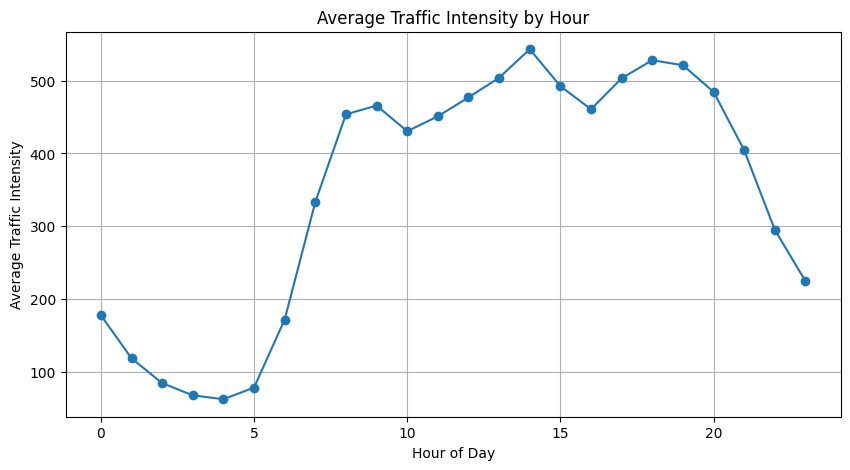

<Figure size 640x480 with 0 Axes>

In [110]:
import matplotlib.pyplot as plt

traffic_by_hour = con.execute(f"""
SELECT
    EXTRACT(HOUR FROM DATETIME) AS hour,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY hour
ORDER BY hour
""").df()

plt.figure(figsize=(10,5))
plt.plot(
    traffic_by_hour["hour"],
    traffic_by_hour["avg_traffic"],
    marker="o"
)
plt.title("Average Traffic Intensity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Intensity")
plt.grid(True)
plt.show()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/traffic_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

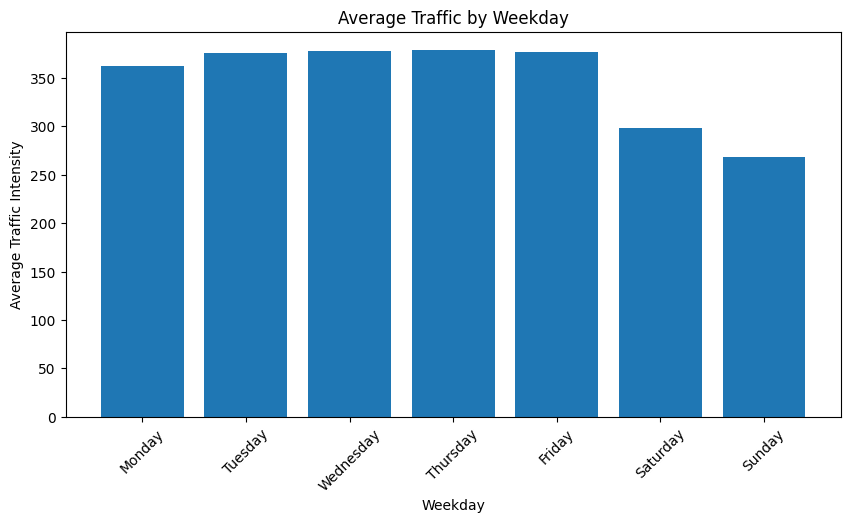

<Figure size 640x480 with 0 Axes>

In [111]:
traffic_by_day = con.execute(f"""
SELECT
    DAYNAME(DATETIME) AS weekday,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY weekday
""").df()

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

traffic_by_day["weekday"] = pd.Categorical(
    traffic_by_day["weekday"],
    categories=weekday_order,
    ordered=True
)

traffic_by_day = traffic_by_day.sort_values("weekday")

plt.figure(figsize=(10,5))
plt.bar(
    traffic_by_day["weekday"],
    traffic_by_day["avg_traffic"]
)
plt.title("Average Traffic by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Traffic Intensity")
plt.xticks(rotation=45)
plt.show()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/traffic_by_Weekday.png",
    dpi=300,
    bbox_inches="tight"
)

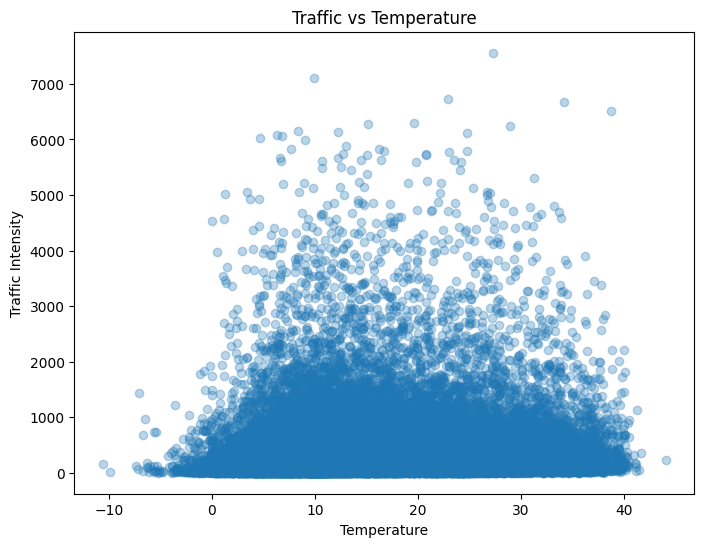

<Figure size 640x480 with 0 Axes>

In [112]:
corr_sample = con.execute(f"""
SELECT
    TEMPERATURE,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL
USING SAMPLE 50000 ROWS
""").df()

plt.figure(figsize=(8,6))
plt.scatter(
    corr_sample["TEMPERATURE"],
    corr_sample["TRAFFIC_INTENSITY"],
    alpha=0.3
)
plt.xlabel("Temperature")
plt.ylabel("Traffic Intensity")
plt.title("Traffic vs Temperature")
plt.show()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/traffic_vs_Temperature.png",
    dpi=300,
    bbox_inches="tight"
)

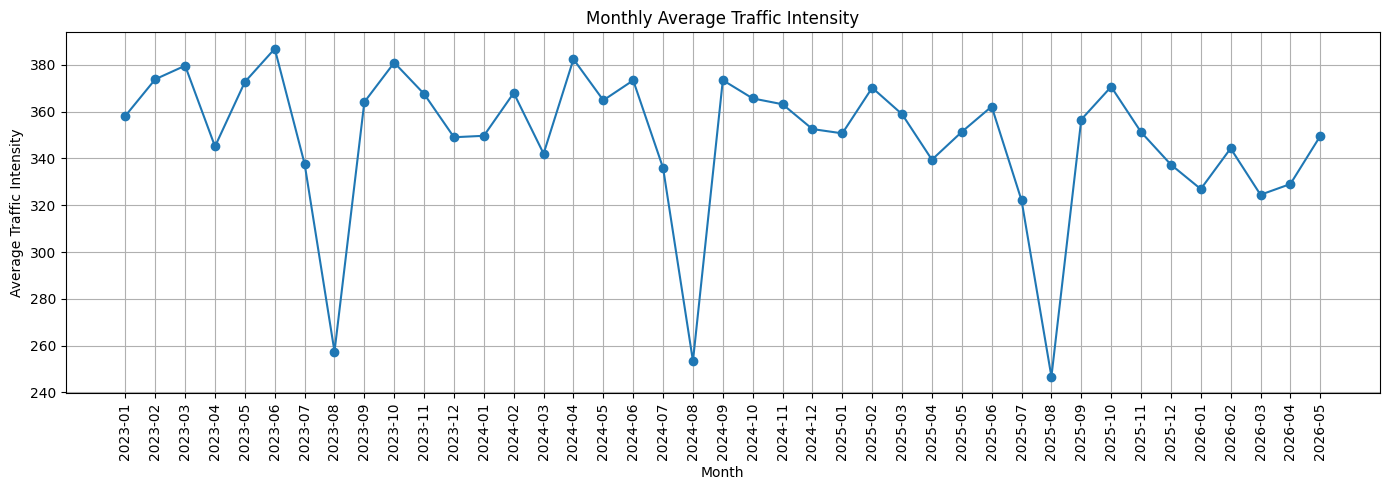

<Figure size 640x480 with 0 Axes>

In [113]:
monthly = con.execute(f"""
SELECT
    YEAR(DATETIME) AS year,
    MONTH(DATETIME) AS month,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY
    YEAR(DATETIME),
    MONTH(DATETIME)
ORDER BY
    year,
    month
""").df()

monthly["year_month"] = (
    monthly["year"].astype(str)
    + "-"
    + monthly["month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly["year_month"],
    monthly["avg_traffic"],
    marker="o"
)

plt.title("Monthly Average Traffic Intensity")
plt.xlabel("Month")
plt.ylabel("Average Traffic Intensity")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/Monthly_Average_traffic.png",
    dpi=300,
    bbox_inches="tight"
)

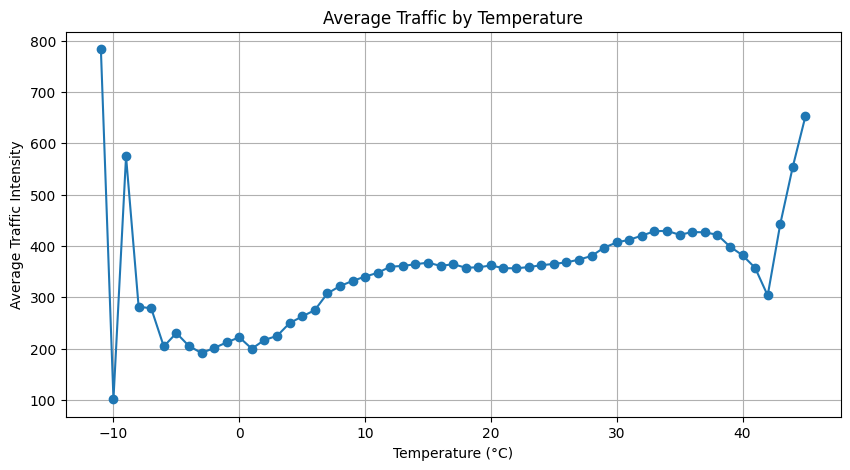

<Figure size 640x480 with 0 Axes>

In [114]:
temp_bins = con.execute(f"""
SELECT
    ROUND(TEMPERATURE) AS temp,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL
GROUP BY ROUND(TEMPERATURE)
ORDER BY temp
""").df()

plt.figure(figsize=(10,5))
plt.plot(
    temp_bins["temp"],
    temp_bins["avg_traffic"],
    marker="o"
)

plt.title("Average Traffic by Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Average Traffic Intensity")
plt.grid(True)
plt.show()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/Average_Traffic_By_Temperature.png",
    dpi=300,
    bbox_inches="tight"
)

In [115]:
#Missing values
missing = con.execute(f"""
SELECT
    COUNT(*) AS total_rows,

    100.0 * (COUNT(*) - COUNT(TEMPERATURE)) / COUNT(*) AS temp_missing_pct,
    100.0 * (COUNT(*) - COUNT(PRECIPITATION)) / COUNT(*) AS precip_missing_pct,
    100.0 * (COUNT(*) - COUNT(WIND_SPEED)) / COUNT(*) AS wind_missing_pct,
    100.0 * (COUNT(*) - COUNT(SOLAR_RADIATION)) / COUNT(*) AS solar_missing_pct
FROM read_parquet('{hourly}')
""").df()
print('Missing values in Percentage')
missing

Missing values in Percentage


,total_rows,temp_missing_pct,precip_missing_pct,wind_missing_pct,solar_missing_pct
0,135056283,9.064881,61.307187,67.515191,73.502015


In [116]:
weather_coverage = con.execute(f"""
SELECT
    NEAREST_WEATHER_STATION_NAME,

    COUNT(*) AS rows,

    COUNT(TEMPERATURE) AS temp_rows,
    COUNT(PRECIPITATION) AS precip_rows,
    COUNT(WIND_SPEED) AS wind_rows,
    COUNT(SOLAR_RADIATION) AS solar_rows

FROM read_parquet('{hourly}')

GROUP BY NEAREST_WEATHER_STATION_NAME

ORDER BY rows DESC
""").df()

weather_coverage.head(27)

,NEAREST_WEATHER_STATION_NAME,rows,temp_rows,precip_rows,wind_rows,solar_rows
0,J.M.D. Hortaleza,14358889,12859130,12850042,12805957,12859130
1,Arturo Soria,13764029,13352100,0,0,0
2,Barrio del Pilar,11464305,11078083,11029892,0,0
3,J.M.D.Chamartin,9459972,7873405,0,0,0
4,Farolillo,9408464,9110662,0,0,0
5,Cuatro Caminos,7637335,7408423,0,0,0
6,Matadero 01,7009310,6386095,0,0,0
7,J.M.D.Vallecas 1,6281055,5758471,0,0,0
8,Plaza Elíptica,5744556,5572963,5573219,5429087,0
9,Escuelas Aguirre,5612476,5381177,0,0,0


In [117]:
corr = con.execute(f"""
SELECT
    CORR(TRAFFIC_INTENSITY, TEMPERATURE) AS traffic_temp,
    CORR(TRAFFIC_INTENSITY, RELATIVE_HUMIDITY) AS traffic_humidity,
    CORR(TRAFFIC_INTENSITY, PRECIPITATION) AS traffic_precip,
    CORR(TRAFFIC_INTENSITY, WIND_SPEED) AS traffic_wind,
    CORR(TRAFFIC_INTENSITY, BAROMETRIC_PRESSURE) AS traffic_pressure
FROM read_parquet('{hourly}')
""").df()

corr

,traffic_temp,traffic_humidity,traffic_precip,traffic_wind,traffic_pressure
0,0.068852,-0.083208,0.003037,0.088601,-0.002085


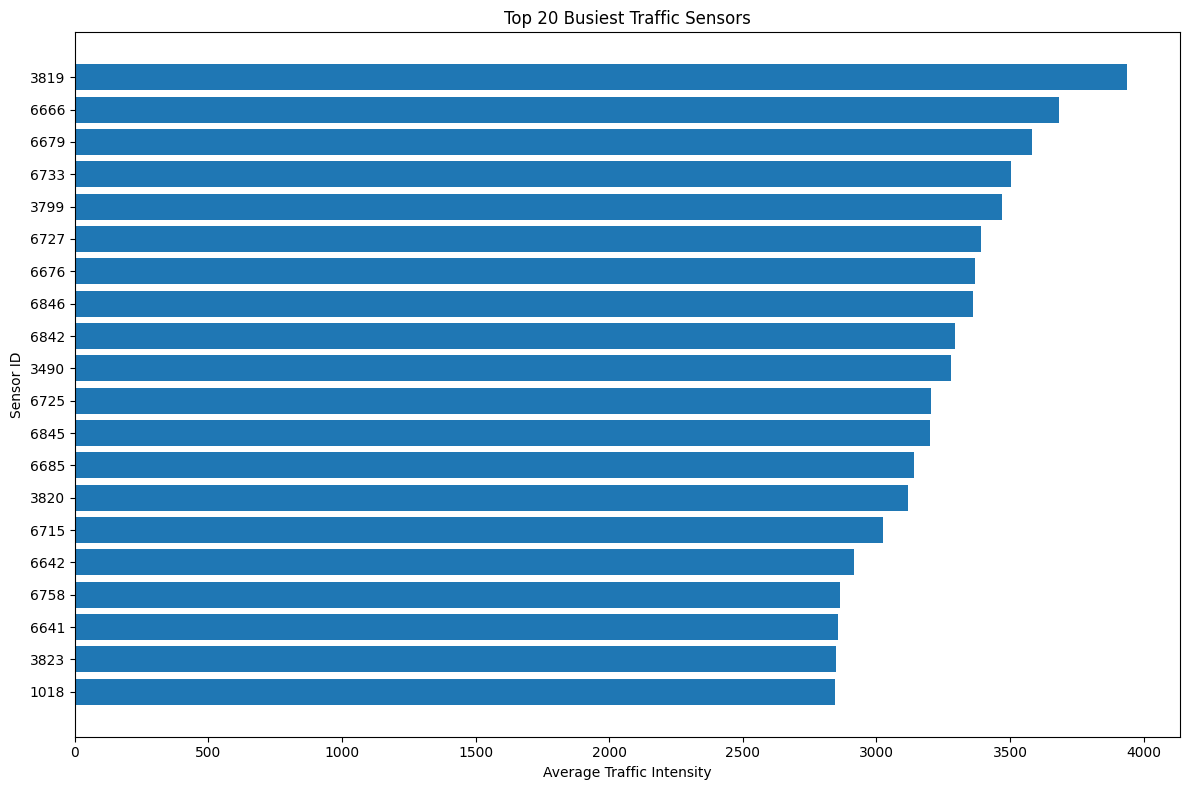

In [118]:
top_sensors = con.execute(f"""
SELECT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID, LONGITUDE, LATITUDE
ORDER BY avg_traffic DESC
LIMIT 20
""").df()

top_sensors

plt.figure(figsize=(12, 8))

plt.barh(
    top_sensors["SENSOR_ID"].astype(str),
    top_sensors["avg_traffic"]
)

plt.title("Top 20 Busiest Traffic Sensors")
plt.xlabel("Average Traffic Intensity")
plt.ylabel("Sensor ID")

plt.gca().invert_yaxis()  # highest traffic on top

plt.tight_layout()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/top_20_busiest_sensors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [119]:
top_sensors_location = con.execute(f"""
SELECT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
GROUP BY
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
ORDER BY avg_traffic DESC
LIMIT 20
""").df()

top_sensors_location

,SENSOR_ID,LONGITUDE,LATITUDE,avg_traffic
0,3819,-3.659560,40.440890,3938.973018
1,6666,-3.659215,40.421738,3681.994357
2,6679,-3.674823,40.393664,3583.723314
3,6733,-3.659647,40.435274,3502.349843
4,3799,-3.660816,40.431088,3471.231421
5,6727,-3.660936,40.445659,3391.298600
6,6676,-3.667784,40.400672,3367.455290
7,6846,-3.720037,40.399618,3361.858761
8,6842,-3.721636,40.407497,3293.197361
9,3490,-3.661244,40.414223,3277.219334


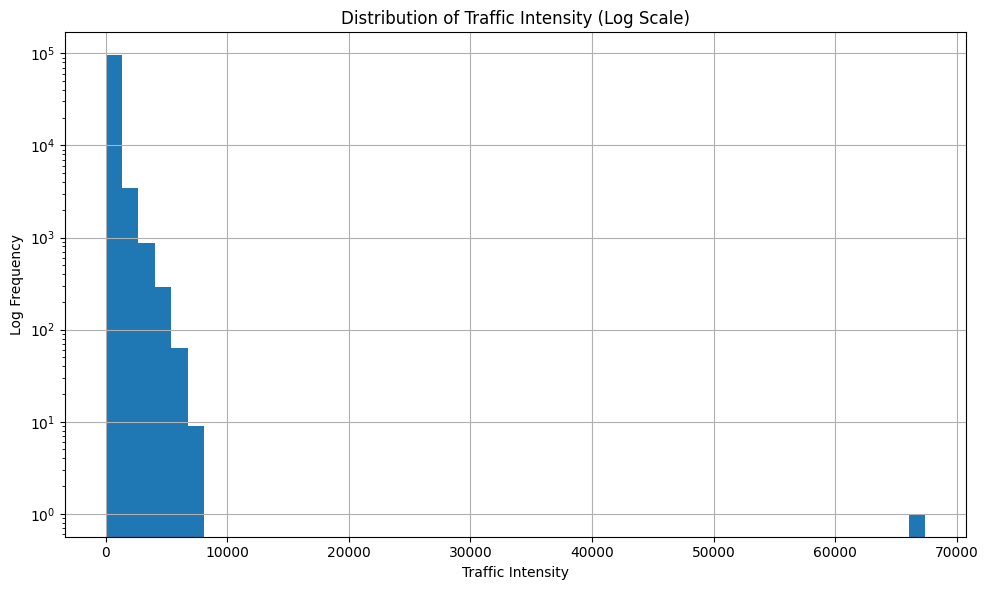

In [120]:
traffic_dist = con.execute(f"""
SELECT
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
USING SAMPLE 100000 ROWS
""").df()

plt.figure(figsize=(10, 6))

plt.hist(
    traffic_dist["TRAFFIC_INTENSITY"],
    bins=50
)

plt.yscale("log")

plt.title("Distribution of Traffic Intensity (Log Scale)")
plt.xlabel("Traffic Intensity")
plt.ylabel("Log Frequency")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "/home/iai-labor/traffic_project/figures/traffic_intensity_distribution_log.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [121]:
traffic_stats = con.execute(f"""
SELECT
    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    AVG(TRAFFIC_INTENSITY) AS mean_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    STDDEV(TRAFFIC_INTENSITY) AS std_traffic
FROM read_parquet('{hourly}')
""").df()

traffic_stats

,min_traffic,max_traffic,mean_traffic,median_traffic,std_traffic
0,0.0,91368.333333,348.074904,158.5,574.255412


In [122]:
con.execute(f"""
SELECT
    SENSOR_ID,
    DATETIME,
    TRAFFIC_INTENSITY,
    INTEGRATION_PERIOD
FROM read_parquet('{hourly}')
ORDER BY TRAFFIC_INTENSITY DESC
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,TRAFFIC_INTENSITY,INTEGRATION_PERIOD
0,7023,2026-02-20 22:00:00,91368.333333,7.000000
1,7023,2026-02-17 13:00:00,91338.250000,8.500000
2,7023,2026-02-20 23:00:00,91269.250000,4.000000
3,7023,2026-02-17 03:00:00,91191.500000,15.000000
4,7023,2026-02-21 07:00:00,91068.000000,3.000000
5,7023,2026-02-17 02:00:00,90986.250000,15.000000
6,5465,2023-02-14 15:00:00,90910.000000,10.000000
7,7023,2026-02-17 14:00:00,90900.250000,10.750000
8,7023,2026-02-17 04:00:00,90847.750000,15.000000
9,7023,2026-02-21 10:00:00,90835.500000,5.000000


In [123]:
con.execute(f"""
SELECT
    SENSOR_ID,
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
ORDER BY TRAFFIC_INTENSITY DESC
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,TRAFFIC_INTENSITY
0,7023,2026-02-20 22:00:00,91368.333333
1,7023,2026-02-17 13:00:00,91338.250000
2,7023,2026-02-20 23:00:00,91269.250000
3,7023,2026-02-17 03:00:00,91191.500000
4,7023,2026-02-21 07:00:00,91068.000000
5,7023,2026-02-17 02:00:00,90986.250000
6,5465,2023-02-14 15:00:00,90910.000000
7,7023,2026-02-17 14:00:00,90900.250000
8,7023,2026-02-17 04:00:00,90847.750000
9,7023,2026-02-21 10:00:00,90835.500000


In [124]:
con.execute(f"""
SELECT
    SENSOR_ID,
    DATETIME,
    TRAFFIC_INTENSITY,
    INTEGRATION_PERIOD
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 7023
ORDER BY TRAFFIC_INTENSITY DESC
LIMIT 20
""").df()

,SENSOR_ID,DATETIME,TRAFFIC_INTENSITY,INTEGRATION_PERIOD
0,7023,2026-02-20 22:00:00,91368.333333,7.000000
1,7023,2026-02-17 13:00:00,91338.250000,8.500000
2,7023,2026-02-20 23:00:00,91269.250000,4.000000
3,7023,2026-02-17 03:00:00,91191.500000,15.000000
4,7023,2026-02-21 07:00:00,91068.000000,3.000000
5,7023,2026-02-17 02:00:00,90986.250000,15.000000
6,7023,2026-02-17 14:00:00,90900.250000,10.750000
7,7023,2026-02-17 04:00:00,90847.750000,15.000000
8,7023,2026-02-21 10:00:00,90835.500000,5.000000
9,7023,2026-02-20 06:00:00,90712.000000,6.750000


In [125]:
con.execute("""
SELECT *
FROM read_parquet('/home/iai-labor/traffic_project/traffic_weather_parts/**/*.parquet')
WHERE SENSOR_ID = 7023
AND DATE_TRUNC('hour', DATETIME) = TIMESTAMP '2026-02-17 13:00:00'
LIMIT 50
""").df()

,SENSOR_ID,DATETIME,ELEMENT_TYPE,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,ERROR_FLAG,INTEGRATION_PERIOD,LONGITUDE,...,NEAREST_WEATHER_STATION_CODE,NEAREST_WEATHER_STATION_NAME,DISTANCE_TO_WEATHER_KM,BAROMETRIC_PRESSURE,PRECIPITATION,RELATIVE_HUMIDITY,SOLAR_RADIATION,TEMPERATURE,WIND_DIRECTION,WIND_SPEED
0,7023,2026-02-17 13:00:00,URB,91527,17.0,100,0.0,N,6,-3.686796,...,28079114,Matadero 01,1.486173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7023,2026-02-17 13:15:00,URB,91560,17.0,100,0.0,N,6,-3.686796,...,28079114,Matadero 01,1.486173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7023,2026-02-17 13:30:00,URB,91559,17.0,100,0.0,N,13,-3.686796,...,28079114,Matadero 01,1.486173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,7023,2026-02-17 13:45:00,URB,90707,17.0,100,0.0,N,9,-3.686796,...,28079114,Matadero 01,1.486173,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [126]:
con.execute(f"""
SELECT
    COUNT(DISTINCT SENSOR_ID)
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY > 50000
""").df()

,count(DISTINCT SENSOR_ID)
0,11


In [127]:
con.execute(f"""
SELECT
    SENSOR_ID,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID
ORDER BY max_traffic DESC
LIMIT 20
""").df()

,SENSOR_ID,max_traffic
0,7023,91368.333333
1,5465,90910.000000
2,3947,90813.000000
3,5767,89515.500000
4,5468,89071.500000
5,6095,73800.000000
6,5470,66255.000000
7,5427,65960.000000
8,5824,58342.000000
9,10463,50965.000000


In [128]:
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    AVG(AVERAGE_SPEED) AS avg_speed,
    AVG(LOAD) AS avg_load
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (
    7023,5465,3947,5767,5468,
    6095,5470,5427,5824,10463,7112
)
GROUP BY SENSOR_ID
ORDER BY max_traffic DESC
""").df()

,SENSOR_ID,rows,avg_traffic,max_traffic,avg_speed,avg_load
0,7023,27176,749.455843,91368.333333,0.0,2.401065
1,5465,29788,495.167139,90910.000000,0.0,13.711260
2,3947,29051,1069.949308,90813.000000,0.0,32.635469
3,5767,29791,730.321442,89515.500000,0.0,11.396124
4,5468,28153,902.367400,89071.500000,0.0,23.377920
5,6095,29163,606.892975,73800.000000,0.0,20.626550
6,5470,27972,342.523425,66255.000000,0.0,10.950364
7,5427,28871,1362.926420,65960.000000,0.0,30.793371
8,5824,29407,1137.724989,58342.000000,0.0,36.760482
9,10463,29658,1222.558882,50965.000000,0.0,25.185363


In [129]:
con.execute(f"""
SELECT
    COUNT(*) AS bad_rows,
    ROUND(
        COUNT(*) * 100.0 /
        (SELECT COUNT(*) FROM read_parquet('{hourly}')),
        6
    ) AS pct_of_dataset
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY > 10000
""").df()

,bad_rows,pct_of_dataset
0,772,0.000572


In [130]:
con.execute(f"""
SELECT
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99)   AS p99,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.999)  AS p999,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.9999) AS p9999,
    MAX(TRAFFIC_INTENSITY)                   AS max_value
FROM read_parquet('{hourly}')
""").df()

,p99,p999,p9999,max_value
0,2951.0,5213.0,6635.0,91368.333333


In [131]:
clean_path = "/home/iai-labor/traffic_project/traffic_weather_hourly_clean"

con.execute(f"""
COPY (
    SELECT *
    FROM read_parquet('{hourly}')
    WHERE TRAFFIC_INTENSITY <= 10000
)
TO '{clean_path}'
(FORMAT PARQUET);
""")

In [132]:
con.execute(f"""
SELECT
    COUNT(*) AS rows,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{clean_path}')
""").df()

,rows,max_traffic
0,135055511,9981.5


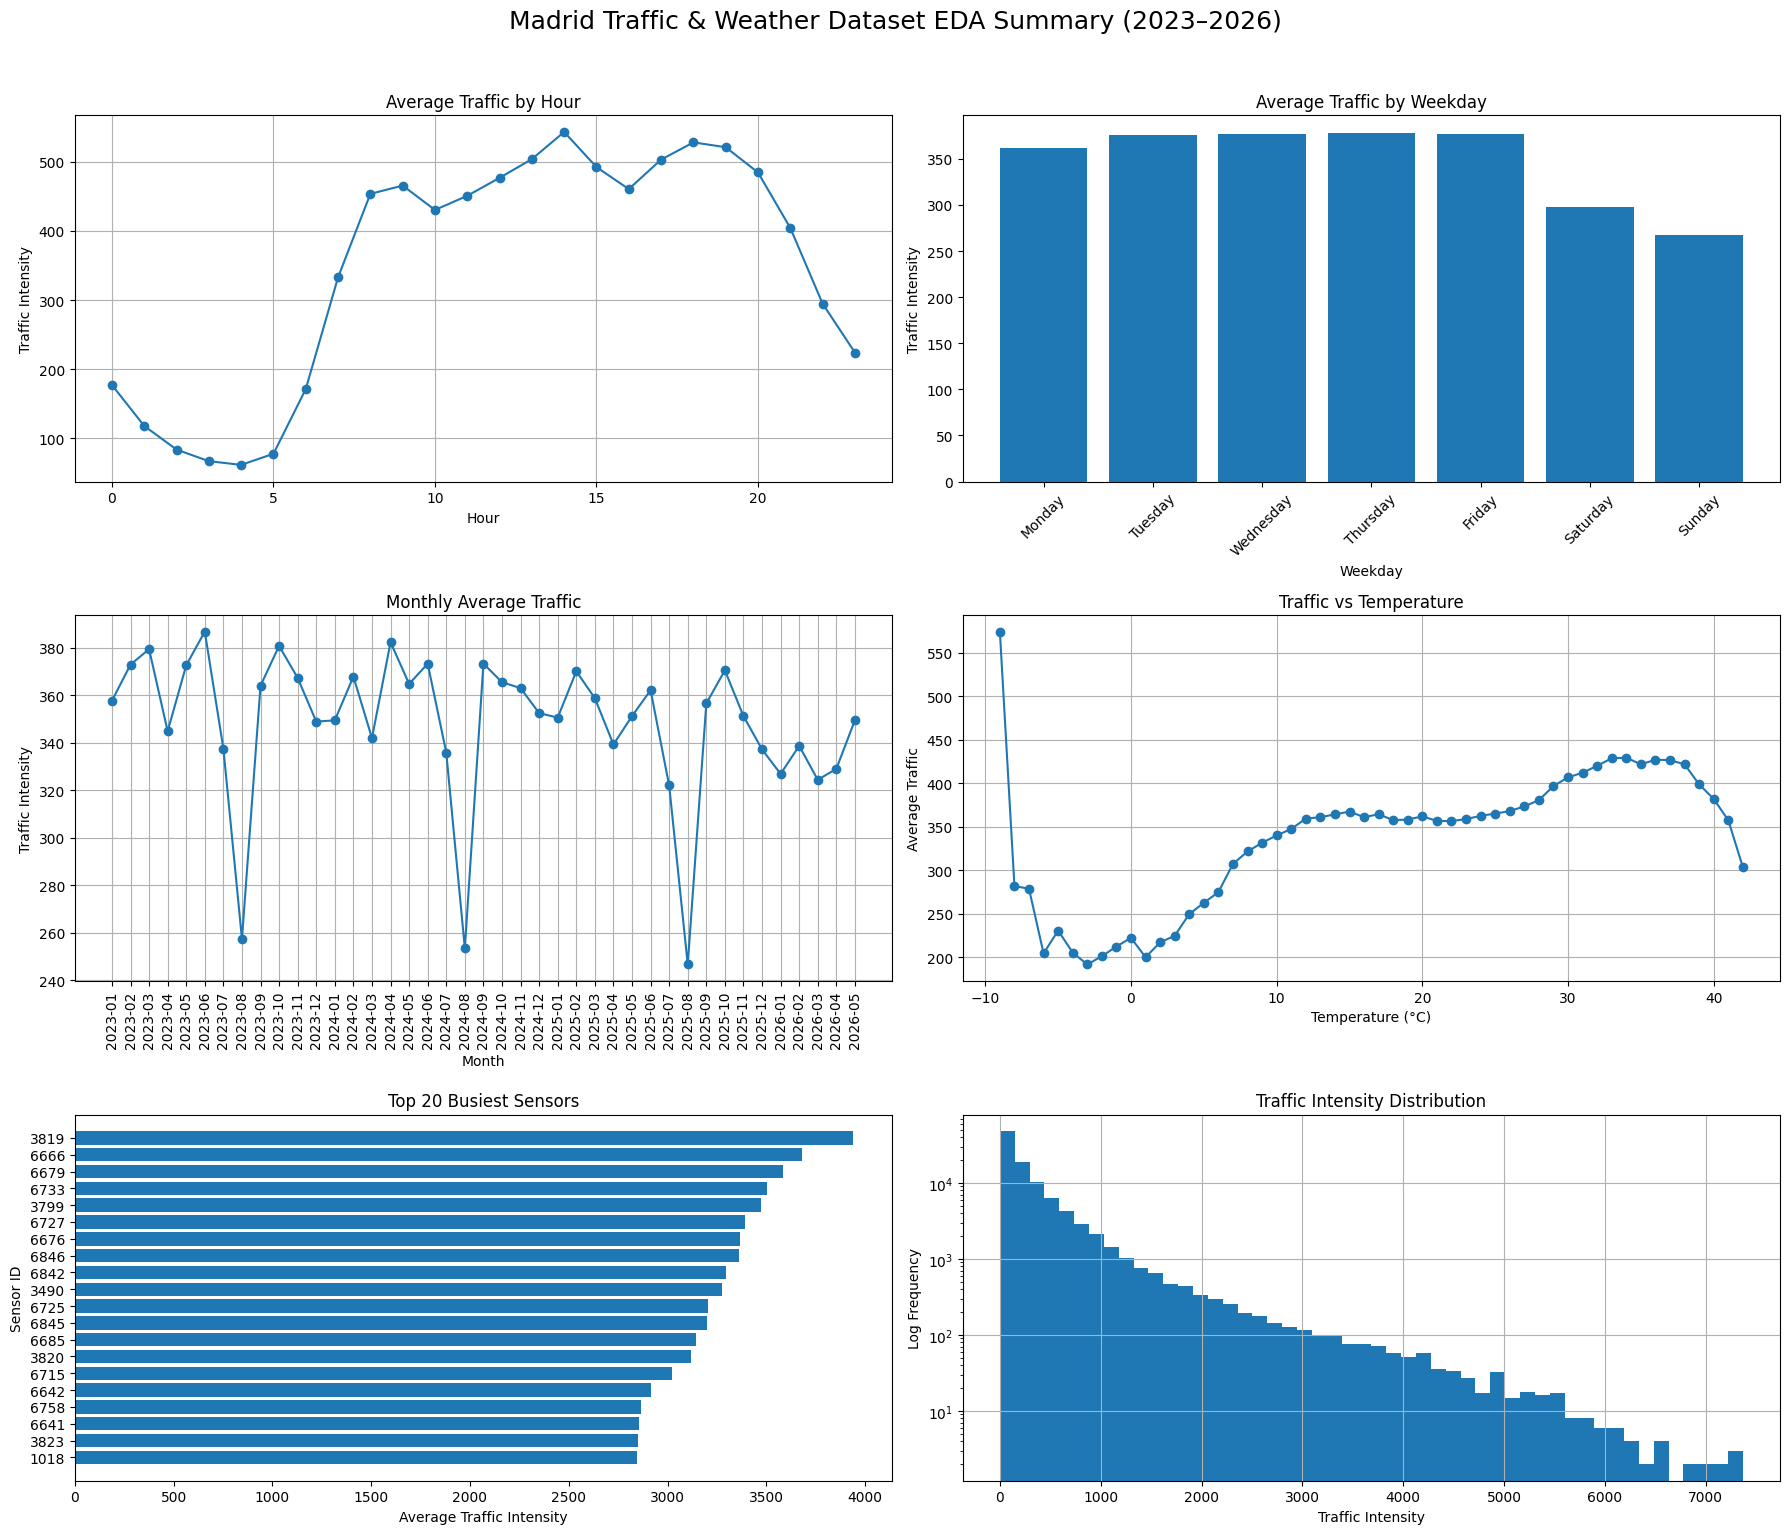

Saved dashboard to: /home/iai-labor/traffic_project/figures/EDA_Summary_Dashboard.png


In [137]:
from pathlib import Path
import matplotlib.pyplot as plt

# Paths
hourly = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet"

figures_dir = Path("/home/iai-labor/traffic_project/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Traffic by hour
traffic_by_hour = con.execute(f"""
SELECT
    EXTRACT(HOUR FROM DATETIME) AS hour,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY <= 10000
GROUP BY hour
ORDER BY hour
""").df()

# 2. Traffic by weekday
traffic_by_day = con.execute(f"""
SELECT
    DAYNAME(DATETIME) AS weekday,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY <= 10000
GROUP BY weekday
""").df()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

traffic_by_day["weekday"] = traffic_by_day["weekday"].astype(str)
traffic_by_day["weekday"] = traffic_by_day["weekday"].astype("category")
traffic_by_day["weekday"] = traffic_by_day["weekday"].cat.set_categories(
    weekday_order,
    ordered=True
)
traffic_by_day = traffic_by_day.sort_values("weekday")

# 3. Monthly trend
monthly = con.execute(f"""
SELECT
    YEAR(DATETIME) AS year,
    MONTH(DATETIME) AS month,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY <= 10000
GROUP BY
    YEAR(DATETIME),
    MONTH(DATETIME)
ORDER BY
    year,
    month
""").df()

monthly["year_month"] = (
    monthly["year"].astype(str)
    + "-"
    + monthly["month"].astype(str).str.zfill(2)
)

# 4. Traffic vs temperature
temp_bins = con.execute(f"""
SELECT
    ROUND(TEMPERATURE) AS temp,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL
  AND TRAFFIC_INTENSITY <= 10000
GROUP BY ROUND(TEMPERATURE)
HAVING COUNT(*) >= 1000
ORDER BY temp
""").df()

# 5. Top 20 sensors
top_sensors = con.execute(f"""
SELECT
    SENSOR_ID,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY <= 10000
GROUP BY SENSOR_ID
ORDER BY avg_traffic DESC
LIMIT 20
""").df()

# 6. Traffic distribution
hist_data = con.execute(f"""
SELECT
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY <= 10000
USING SAMPLE 100000 ROWS
""").df()

# Create dashboard
fig, axes = plt.subplots(3, 2, figsize=(18, 15))

# Traffic by Hour
axes[0, 0].plot(
    traffic_by_hour["hour"],
    traffic_by_hour["avg_traffic"],
    marker="o"
)
axes[0, 0].set_title("Average Traffic by Hour")
axes[0, 0].set_xlabel("Hour")
axes[0, 0].set_ylabel("Traffic Intensity")
axes[0, 0].grid(True)

# Traffic by Weekday
axes[0, 1].bar(
    traffic_by_day["weekday"].astype(str),
    traffic_by_day["avg_traffic"]
)
axes[0, 1].set_title("Average Traffic by Weekday")
axes[0, 1].set_xlabel("Weekday")
axes[0, 1].set_ylabel("Traffic Intensity")
axes[0, 1].tick_params(axis="x", rotation=45)

# Monthly Trend
axes[1, 0].plot(
    monthly["year_month"],
    monthly["avg_traffic"],
    marker="o"
)
axes[1, 0].set_title("Monthly Average Traffic")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Traffic Intensity")
axes[1, 0].tick_params(axis="x", rotation=90)
axes[1, 0].grid(True)

# Traffic vs Temperature
axes[1, 1].plot(
    temp_bins["temp"],
    temp_bins["avg_traffic"],
    marker="o"
)
axes[1, 1].set_title("Traffic vs Temperature")
axes[1, 1].set_xlabel("Temperature (°C)")
axes[1, 1].set_ylabel("Average Traffic")
axes[1, 1].grid(True)

# Top Sensors
axes[2, 0].barh(
    top_sensors["SENSOR_ID"].astype(str),
    top_sensors["avg_traffic"]
)
axes[2, 0].invert_yaxis()
axes[2, 0].set_title("Top 20 Busiest Sensors")
axes[2, 0].set_xlabel("Average Traffic Intensity")
axes[2, 0].set_ylabel("Sensor ID")

# Traffic Distribution
axes[2, 1].hist(
    hist_data["TRAFFIC_INTENSITY"],
    bins=50
)
axes[2, 1].set_yscale("log")
axes[2, 1].set_title("Traffic Intensity Distribution")
axes[2, 1].set_xlabel("Traffic Intensity")
axes[2, 1].set_ylabel("Log Frequency")
axes[2, 1].grid(True)

plt.suptitle(
    "Madrid Traffic & Weather Dataset EDA Summary (2023–2026)",
    fontsize=18,
    y=1.02
)

plt.tight_layout()

output_path = figures_dir / "EDA_Summary_Dashboard.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved dashboard to: {output_path}")

In [1]:
hourly = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet"
import duckdb
con = duckdb.connect()
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    AVG(OCCUPANCY) AS avg_occupancy,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (7023,5465,3947)
GROUP BY SENSOR_ID
ORDER BY max_traffic DESC
""").df()

,SENSOR_ID,rows,avg_traffic,max_traffic,min_traffic,avg_occupancy,avg_load,avg_speed
0,7023,27176,749.455843,91368.333333,0.00,0.334588,2.401065,0.0
1,5465,29788,495.167139,90910.000000,4.75,1.279710,13.711260,0.0
2,3947,29051,1069.949308,90813.000000,0.00,8.029506,32.635469,0.0


In [2]:
con.execute(f"""
SELECT DISTINCT
    SENSOR_ID,
    ELEMENT_TYPE,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (7023,5465,3947)
""").df()

,SENSOR_ID,ELEMENT_TYPE,LONGITUDE,LATITUDE
0,5465,URB,-3.689110,40.464276
1,7023,URB,-3.686796,40.401365
2,3947,URB,-3.688800,40.417908


In [3]:
con.execute(f"""
SELECT
    COUNT(*) AS negative_rows,
    MIN(TRAFFIC_INTENSITY) AS min_value
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY < 0
""").df()

,negative_rows,min_value
0,0,NaN


In [4]:
#Hampel
con.execute(f"""
SELECT
    COUNT(*) AS rows_above_5000,
    COUNT(*) FILTER (
        WHERE TRAFFIC_INTENSITY > 10000
    ) AS rows_above_10000,
    COUNT(*) FILTER (
        WHERE TRAFFIC_INTENSITY > 20000
    ) AS rows_above_20000
FROM read_parquet('{hourly}')
""").df()

,rows_above_5000,rows_above_10000,rows_above_20000
0,135056283,772,387


In [5]:
con.execute(f"""
SELECT
    COUNT(*) FILTER (
        WHERE TRAFFIC_INTENSITY > 5000
    ) AS rows_above_5000,

    COUNT(*) FILTER (
        WHERE TRAFFIC_INTENSITY > 10000
    ) AS rows_above_10000,

    COUNT(*) FILTER (
        WHERE TRAFFIC_INTENSITY > 20000
    ) AS rows_above_20000
FROM read_parquet('{hourly}')
""").df()

,rows_above_5000,rows_above_10000,rows_above_20000
0,174588,772,387


In [6]:
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS high_rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY > 5000
GROUP BY SENSOR_ID
ORDER BY high_rows DESC
LIMIT 20
""").df()

,SENSOR_ID,high_rows,avg_traffic,max_traffic
0,3819,12578,6356.478560,7908.333333
1,6679,11248,5854.925135,7152.000000
2,6666,9514,6211.525235,8215.250000
3,3799,9045,5871.014704,6864.000000
4,6733,8832,5692.596788,6339.000000
5,6727,8572,5865.196910,6739.000000
6,6842,7565,5720.203360,7740.000000
7,6676,7249,5467.649342,6069.000000
8,6725,7062,5679.670289,7160.000000
9,6846,6949,5830.470439,7845.000000


In [7]:
con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows_above_10000,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
WHERE TRAFFIC_INTENSITY > 10000
GROUP BY SENSOR_ID
ORDER BY rows_above_10000 DESC
""").df()

,SENSOR_ID,rows_above_10000,avg_traffic,max_traffic
0,7023,218,76535.932722,91368.333333
1,6070,107,15254.138629,25120.750000
2,10674,63,22287.269841,42949.666667
3,5465,41,51570.554878,90910.000000
4,6069,36,11629.201389,15719.750000
5,4059,33,15101.037879,26872.750000
6,6920,28,12861.598214,20774.000000
7,10298,28,11698.491071,13118.000000
8,5767,26,25367.884615,89515.500000
9,5670,23,11667.717391,15974.750000


In [8]:
con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
ORDER BY DATETIME
""").df()

,DATETIME,TRAFFIC_INTENSITY
0,2023-01-01 00:00:00,2760.0
1,2023-01-01 01:00:00,300.0
2,2023-01-01 02:00:00,300.0
3,2023-01-01 03:00:00,300.0
4,2023-01-01 04:00:00,300.0
...,...,...
28555,2026-05-31 19:00:00,4467.0
28556,2026-05-31 20:00:00,3864.0
28557,2026-05-31 21:00:00,3537.0
28558,2026-05-31 22:00:00,2985.0


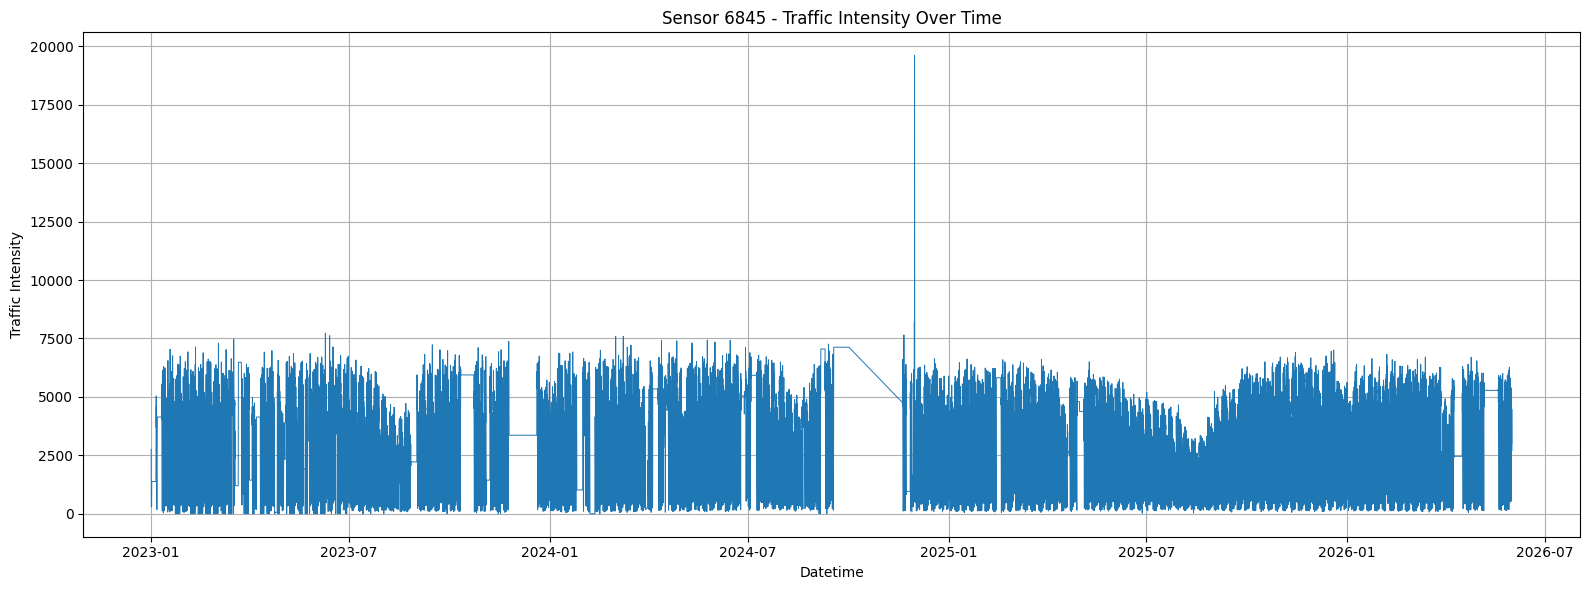

In [9]:
import matplotlib.pyplot as plt

sensor_df = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
ORDER BY DATETIME
""").df()

plt.figure(figsize=(16,6))

plt.plot(
    sensor_df["DATETIME"],
    sensor_df["TRAFFIC_INTENSITY"],
    linewidth=0.7
)

plt.title("Sensor 6845 - Traffic Intensity Over Time")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.grid(True)

plt.tight_layout()
plt.show()

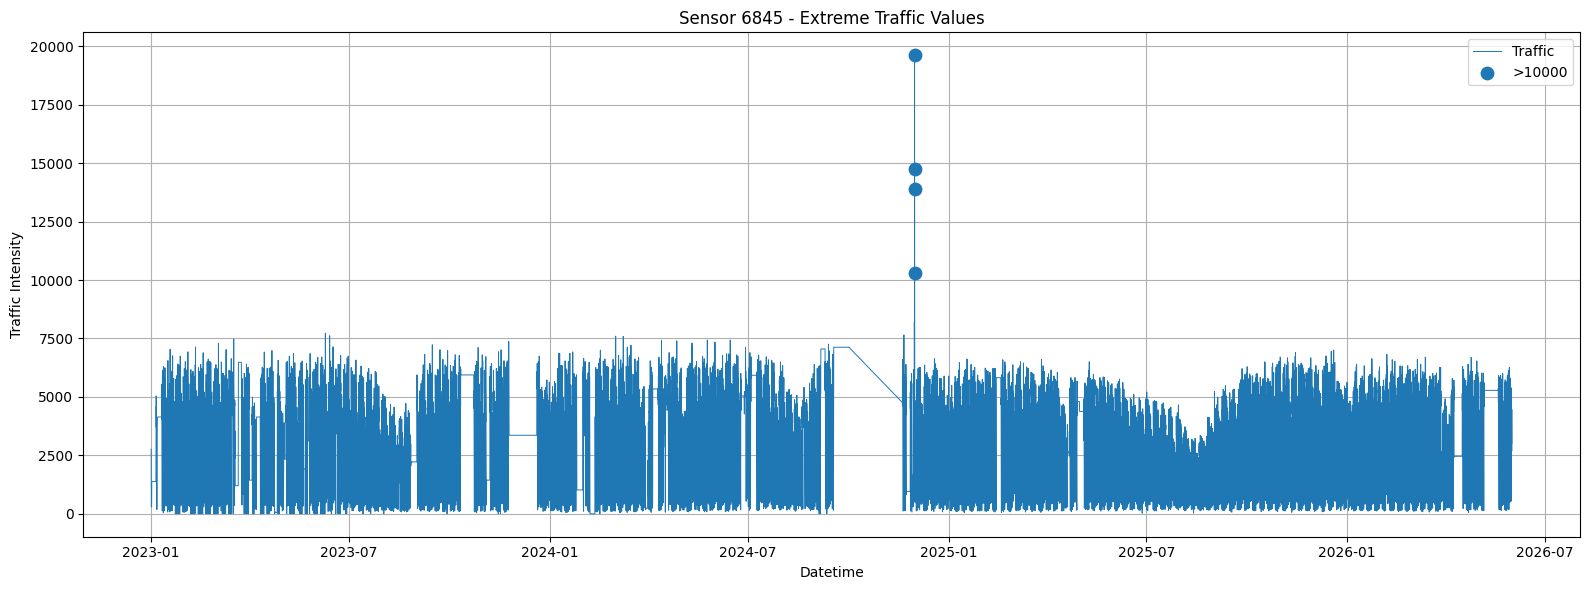

In [10]:
import matplotlib.pyplot as plt

sensor_df = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
ORDER BY DATETIME
""").df()

outliers = sensor_df[
    sensor_df["TRAFFIC_INTENSITY"] > 10000
]

plt.figure(figsize=(16,6))

plt.plot(
    sensor_df["DATETIME"],
    sensor_df["TRAFFIC_INTENSITY"],
    linewidth=0.7,
    label="Traffic"
)

plt.scatter(
    outliers["DATETIME"],
    outliers["TRAFFIC_INTENSITY"],
    s=80,
    label=">10000",
    zorder=5
)

plt.title("Sensor 6845 - Extreme Traffic Values")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
  AND TRAFFIC_INTENSITY > 10000
ORDER BY DATETIME
""").df()

,DATETIME,TRAFFIC_INTENSITY
0,2024-11-30 12:00:00,19614.0
1,2024-11-30 13:00:00,14766.0
2,2024-11-30 14:00:00,13878.0
3,2024-11-30 17:00:00,10312.0


In [12]:
con.execute(f"""
SELECT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (
    6845,
    6842,
    6844,
    6846
)
GROUP BY
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
ORDER BY SENSOR_ID
""").df()

,SENSOR_ID,LONGITUDE,LATITUDE
0,6842,-3.721636,40.407497
1,6844,-3.723114,40.404492
2,6845,-3.722300,40.405245
3,6846,-3.720037,40.399618


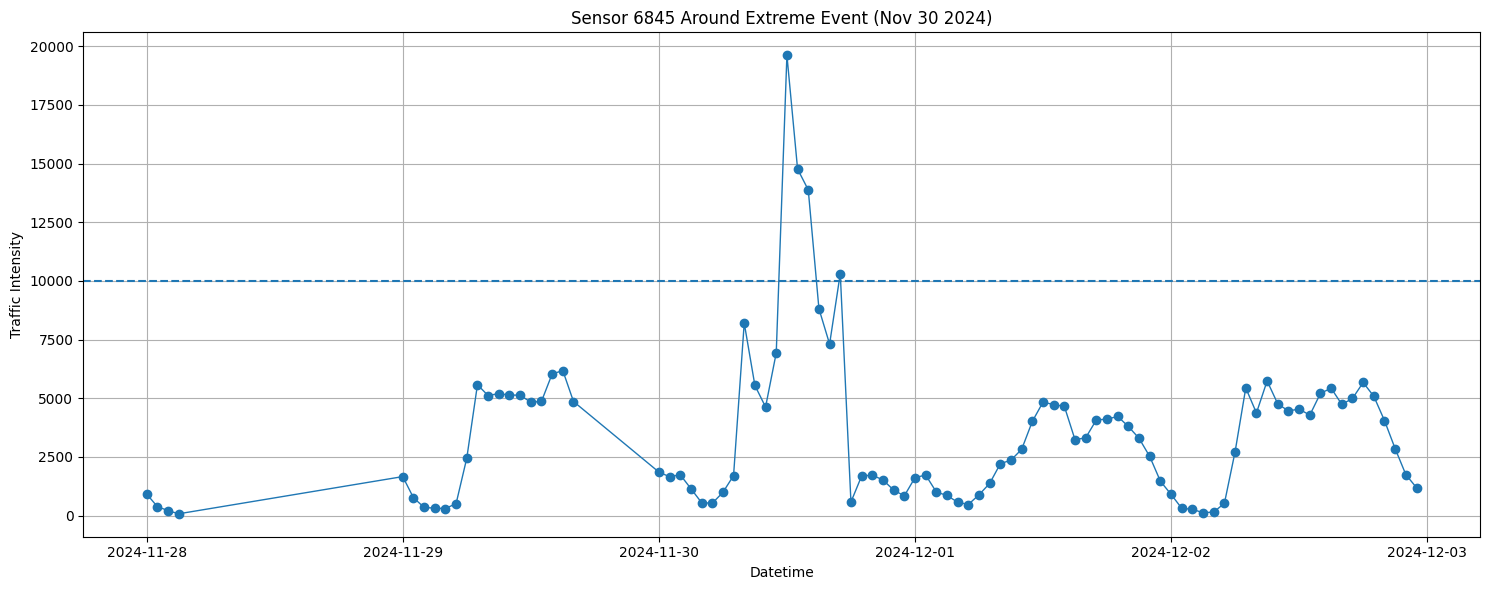

In [13]:
event_window = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
AND DATETIME BETWEEN
    TIMESTAMP '2024-11-28 00:00:00'
    AND
    TIMESTAMP '2024-12-02 23:59:59'
ORDER BY DATETIME
""").df()

import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

plt.plot(
    event_window["DATETIME"],
    event_window["TRAFFIC_INTENSITY"],
    marker="o",
    linewidth=1
)

plt.axhline(
    y=10000,
    linestyle="--"
)

plt.title(
    "Sensor 6845 Around Extreme Event (Nov 30 2024)"
)

plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.grid(True)

plt.tight_layout()
plt.show()

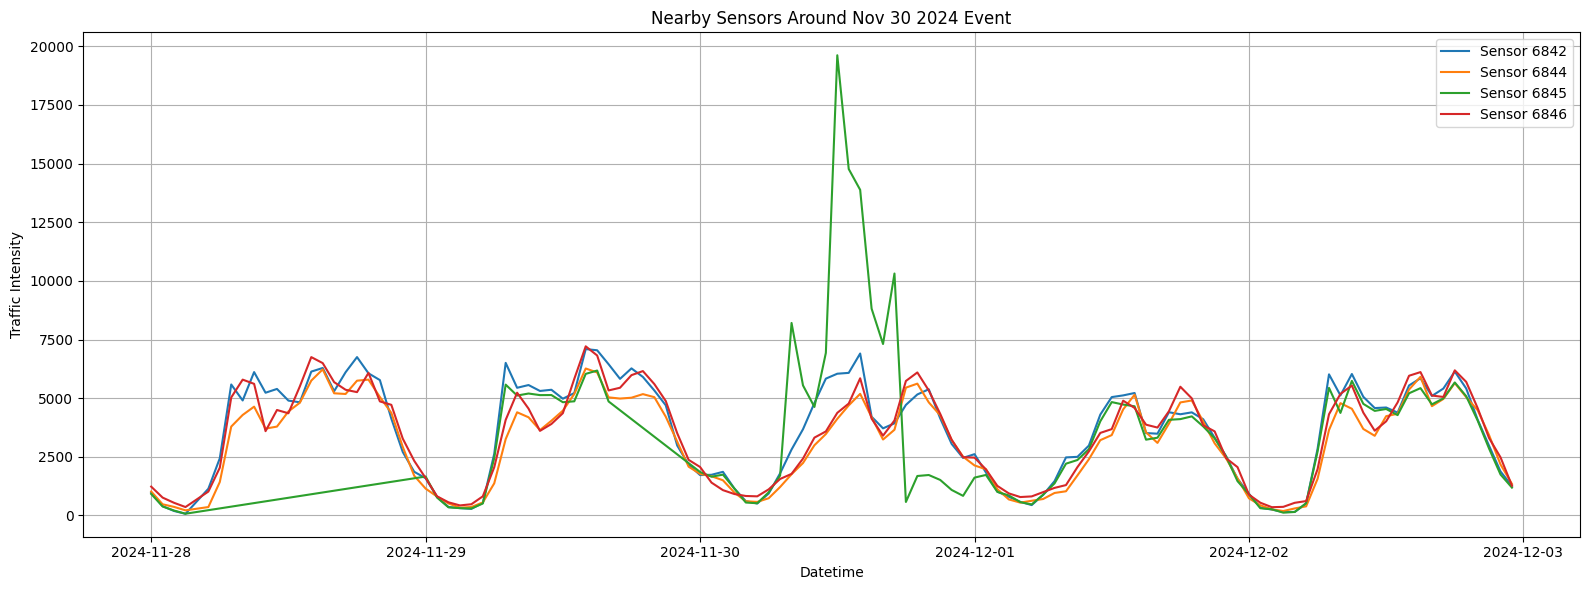

In [14]:
compare_df = con.execute(f"""
SELECT
    DATETIME,
    SENSOR_ID,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (6842,6844,6845,6846)
AND DATETIME BETWEEN
    TIMESTAMP '2024-11-28 00:00:00'
    AND
    TIMESTAMP '2024-12-02 23:59:59'
ORDER BY DATETIME
""").df()

plt.figure(figsize=(16,6))

for sensor in [6842,6844,6845,6846]:

    temp = compare_df[
        compare_df["SENSOR_ID"] == sensor
    ]

    plt.plot(
        temp["DATETIME"],
        temp["TRAFFIC_INTENSITY"],
        label=f"Sensor {sensor}"
    )

plt.title(
    "Nearby Sensors Around Nov 30 2024 Event"
)

plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
sensor_6845_check = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY,
    OCCUPANCY,
    LOAD,
    AVERAGE_SPEED,
    INTEGRATION_PERIOD,
    ERROR_FLAG
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
  AND DATETIME BETWEEN
      TIMESTAMP '2024-11-30 10:00:00'
      AND
      TIMESTAMP '2024-11-30 18:00:00'
ORDER BY DATETIME
""").df()

sensor_6845_check

,DATETIME,TRAFFIC_INTENSITY,OCCUPANCY,LOAD,AVERAGE_SPEED,INTEGRATION_PERIOD,ERROR_FLAG
0,2024-11-30 10:00:00,4626.0,10.25,0.0,69.50,5.0,N
1,2024-11-30 11:00:00,6930.0,12.25,0.0,68.00,5.0,N
2,2024-11-30 12:00:00,19614.0,7.75,0.0,63.25,5.0,N
3,2024-11-30 13:00:00,14766.0,11.75,0.0,63.75,5.0,N
4,2024-11-30 14:00:00,13878.0,17.00,0.0,64.00,5.0,N
5,2024-11-30 15:00:00,8815.5,11.25,0.0,66.00,5.0,N
6,2024-11-30 16:00:00,7308.0,7.00,0.0,65.25,5.0,N
7,2024-11-30 17:00:00,10312.0,20.00,0.0,53.00,5.0,N
8,2024-11-30 18:00:00,576.0,64.00,0.0,31.50,5.0,N


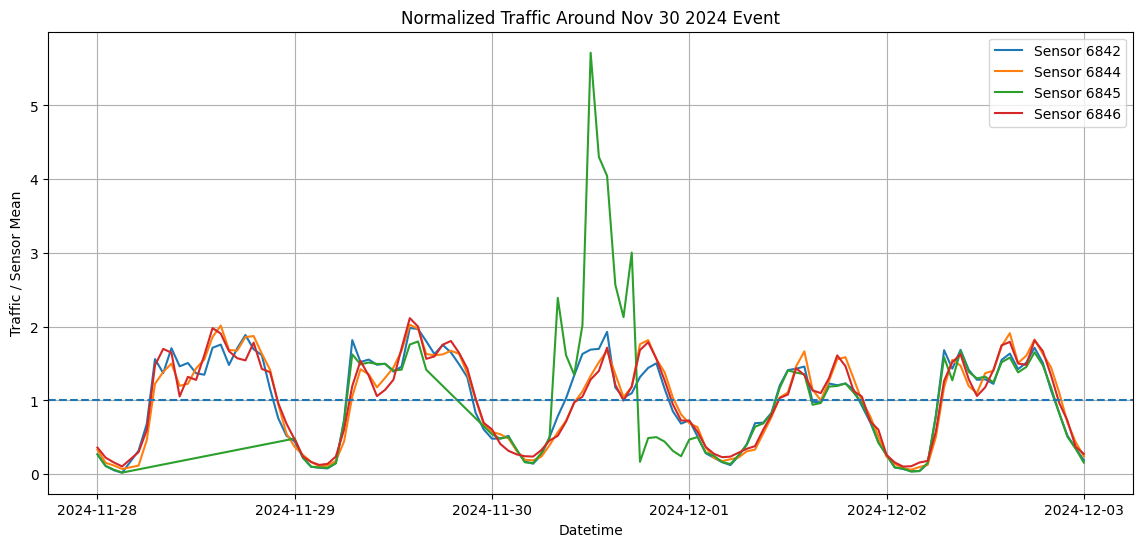

In [16]:
import matplotlib.pyplot as plt

sensors = [6842, 6844, 6845, 6846]

df = con.execute(f"""
SELECT
    SENSOR_ID,
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (6842,6844,6845,6846)
AND DATETIME BETWEEN
    TIMESTAMP '2024-11-28'
    AND TIMESTAMP '2024-12-03'
ORDER BY DATETIME
""").df()

# Normalize by sensor average
df["normalized"] = (
    df.groupby("SENSOR_ID")["TRAFFIC_INTENSITY"]
      .transform(lambda x: x / x.mean())
)

plt.figure(figsize=(14,6))

for sensor in sensors:
    temp = df[df["SENSOR_ID"] == sensor]

    plt.plot(
        temp["DATETIME"],
        temp["normalized"],
        label=f"Sensor {sensor}"
    )

plt.axhline(1, linestyle="--")
plt.title("Normalized Traffic Around Nov 30 2024 Event")
plt.ylabel("Traffic / Sensor Mean")
plt.xlabel("Datetime")
plt.legend()
plt.grid(True)

plt.show()

In [17]:
import pandas as pd
sensor_6845 = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
ORDER BY DATETIME
""").df()

sensor_6845["DATETIME"] = pd.to_datetime(sensor_6845["DATETIME"])
sensor_6845 = sensor_6845.sort_values("DATETIME")

In [18]:
import numpy as np

def hampel_filter(series, window_size=24, n_sigmas=3):
    """
    Hampel filter for outlier detection.

    window_size = number of observations on each side
    n_sigmas = threshold
    """

    k = 1.4826  # scale factor for Gaussian distribution

    outlier_idx = []

    for i in range(window_size, len(series) - window_size):

        window = series[i-window_size:i+window_size+1]

        median = np.median(window)

        mad = k * np.median(np.abs(window - median))

        if mad == 0:
            continue

        if np.abs(series[i] - median) > n_sigmas * mad:
            outlier_idx.append(i)

    return outlier_idx

In [19]:
outliers = hampel_filter(
    sensor_6845["TRAFFIC_INTENSITY"].values,
    window_size=24,
    n_sigmas=3
)

print("Number of outliers:", len(outliers))

Number of outliers: 602


In [20]:
sensor_6845.iloc[outliers][
    ["DATETIME", "TRAFFIC_INTENSITY"]
]

,DATETIME,TRAFFIC_INTENSITY
106,2023-01-05 10:00:00,3993.0
107,2023-01-05 11:00:00,4116.0
108,2023-01-05 12:00:00,4344.0
109,2023-01-05 13:00:00,4509.0
110,2023-01-05 14:00:00,5043.0
...,...,...
27948,2026-05-06 12:00:00,4581.0
27949,2026-05-06 13:00:00,4974.0
28258,2026-05-19 10:00:00,4791.0
28260,2026-05-19 12:00:00,4770.0


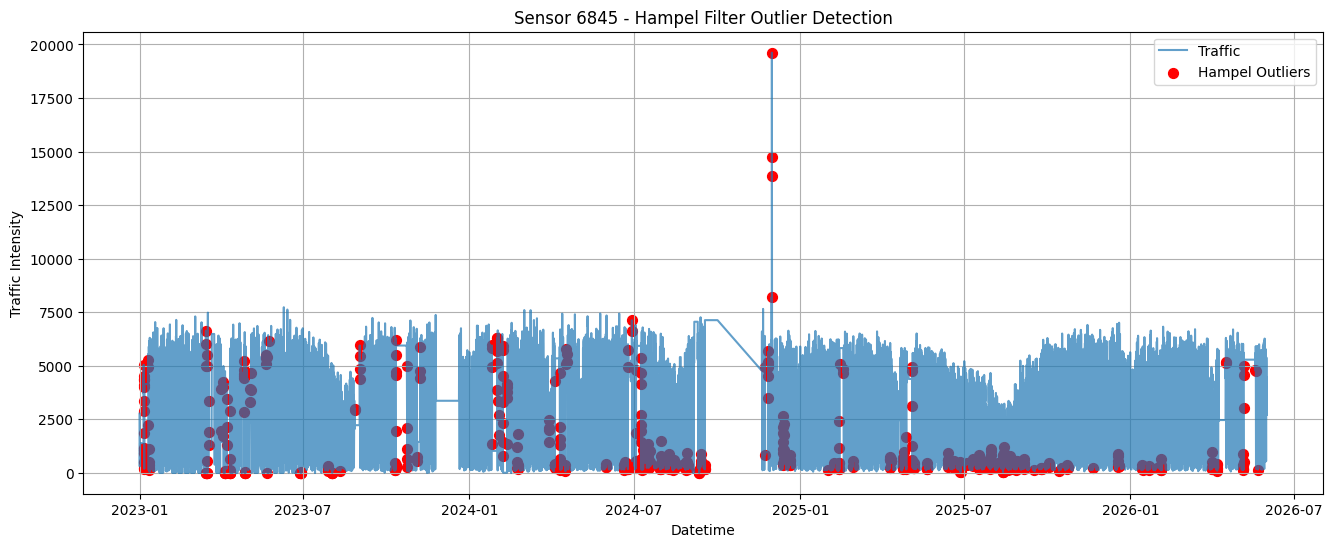

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,6))

plt.plot(
    sensor_6845["DATETIME"],
    sensor_6845["TRAFFIC_INTENSITY"],
    alpha=0.7,
    label="Traffic"
)

plt.scatter(
    sensor_6845.iloc[outliers]["DATETIME"],
    sensor_6845.iloc[outliers]["TRAFFIC_INTENSITY"],
    color="red",
    s=50,
    label="Hampel Outliers"
)

plt.title("Sensor 6845 - Hampel Filter Outlier Detection")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")
plt.legend()
plt.grid(True)

plt.show()

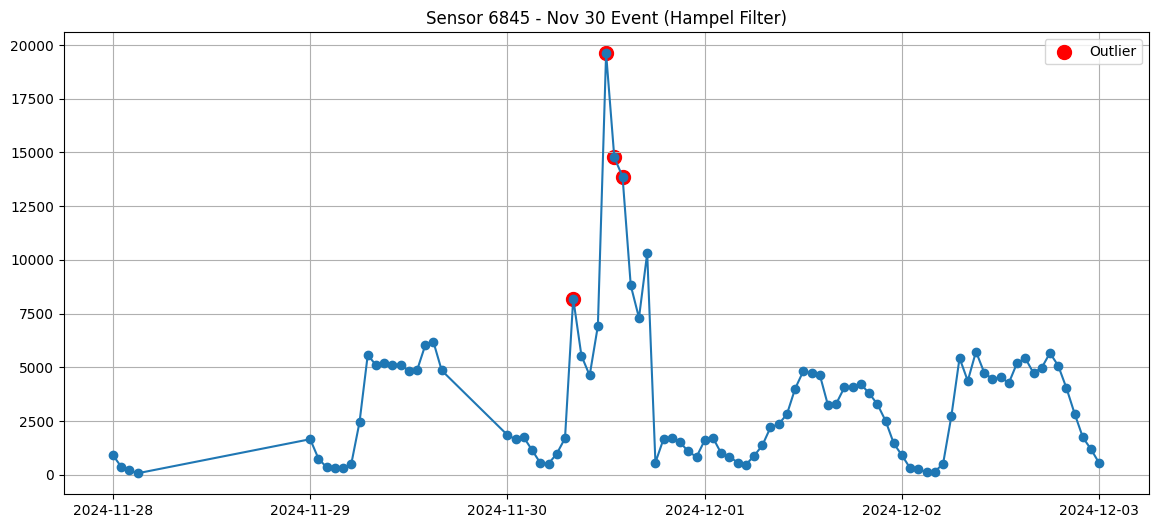

In [22]:
zoom = sensor_6845[
    (sensor_6845["DATETIME"] >= "2024-11-28") &
    (sensor_6845["DATETIME"] <= "2024-12-03")
]

zoom_outliers = zoom[
    zoom.index.isin(sensor_6845.iloc[outliers].index)
]

plt.figure(figsize=(14,6))

plt.plot(
    zoom["DATETIME"],
    zoom["TRAFFIC_INTENSITY"],
    marker="o"
)

plt.scatter(
    zoom_outliers["DATETIME"],
    zoom_outliers["TRAFFIC_INTENSITY"],
    color="red",
    s=100,
    label="Outlier"
)

plt.legend()
plt.grid(True)

plt.title("Sensor 6845 - Nov 30 Event (Hampel Filter)")
plt.show()

In [23]:
sensor_stats = con.execute(f"""
SELECT
    COUNT(*) AS total_rows,
    AVG(TRAFFIC_INTENSITY) AS mean_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.999) AS p999,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
""").df()

sensor_stats

,total_rows,mean_traffic,median_traffic,p99,p999,max_traffic
0,28560,3200.934775,3399.0,7125.0,7140.0,19614.0


In [24]:
extreme = con.execute(f"""
SELECT
    COUNT(*) AS rows_above_10000,
    COUNT(*) * 100.0 / (
        SELECT COUNT(*)
        FROM read_parquet('{hourly}')
        WHERE SENSOR_ID = 6845
    ) AS pct
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6845
AND TRAFFIC_INTENSITY > 10000
""").df()

extreme

,rows_above_10000,pct
0,4,0.014006


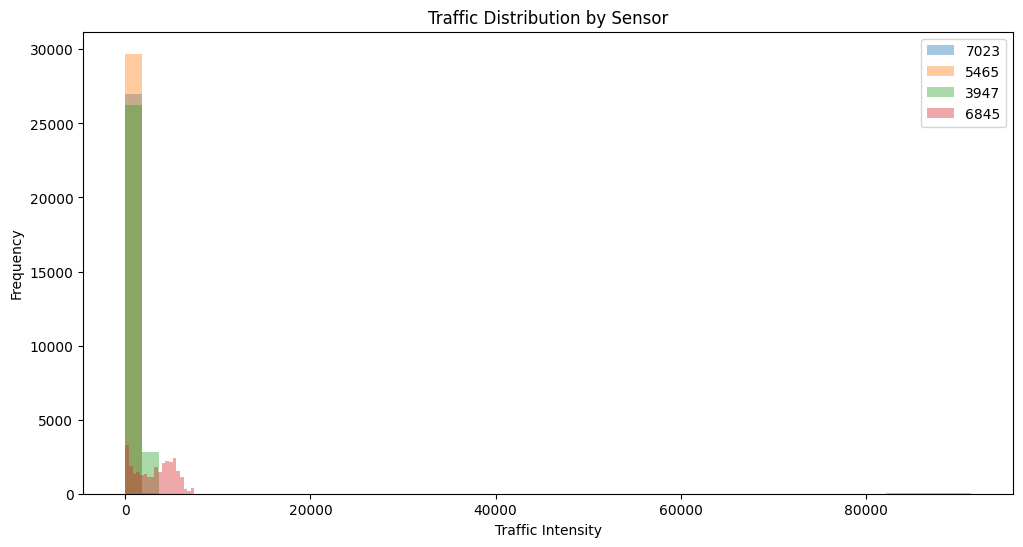

In [25]:
sensor_types = con.execute(f"""
SELECT
    SENSOR_ID,
    ELEMENT_TYPE,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    AVG(OCCUPANCY) AS avg_occupancy,
    AVG(LOAD) AS avg_load,
    AVG(AVERAGE_SPEED) AS avg_speed
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (
    7023,5465,3947,
    6845,6846,6844,6842
)
GROUP BY
    SENSOR_ID,
    ELEMENT_TYPE
ORDER BY max_traffic DESC
""").df()

sensor_types

sensors = [7023,5465,3947,6845]

plt.figure(figsize=(12,6))

for sensor in sensors:

    temp = con.execute(f"""
    SELECT TRAFFIC_INTENSITY
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID = {sensor}
    """).df()

    plt.hist(
        temp["TRAFFIC_INTENSITY"],
        bins=50,
        alpha=0.4,
        label=f"{sensor}"
    )

plt.legend()
plt.title("Traffic Distribution by Sensor")
plt.xlabel("Traffic Intensity")
plt.ylabel("Frequency")
plt.show()

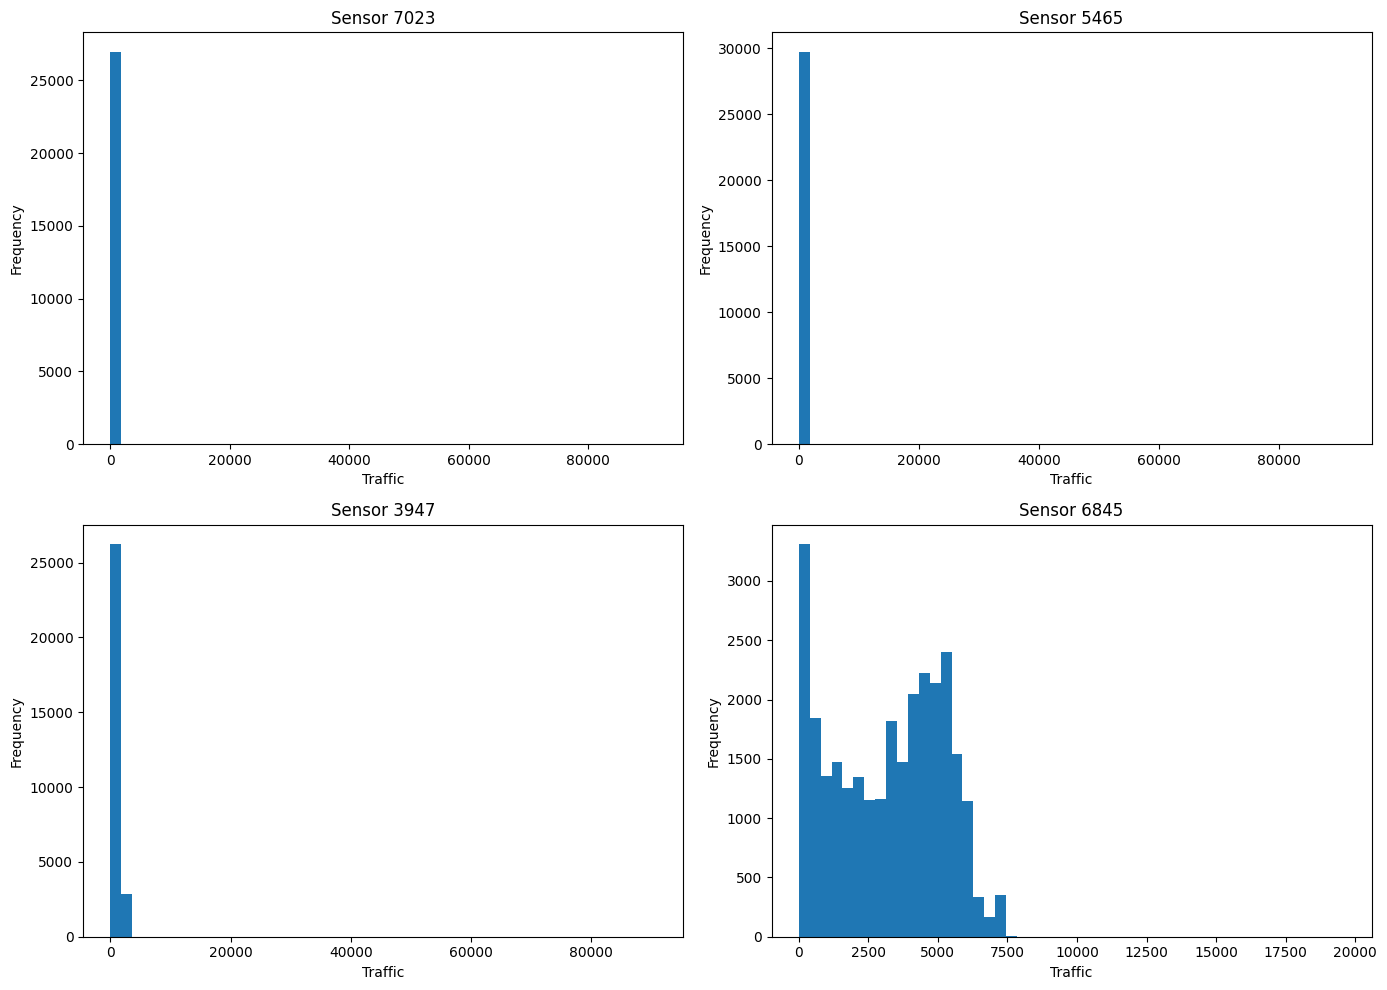

In [26]:
import matplotlib.pyplot as plt

sensors = [7023, 5465, 3947, 6845]

fig, axes = plt.subplots(2, 2, figsize=(14,10))

for ax, sensor in zip(axes.flatten(), sensors):

    temp = con.execute(f"""
    SELECT TRAFFIC_INTENSITY
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID = {sensor}
    """).df()

    ax.hist(
        temp["TRAFFIC_INTENSITY"],
        bins=50
    )

    ax.set_title(f"Sensor {sensor}")
    ax.set_xlabel("Traffic")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

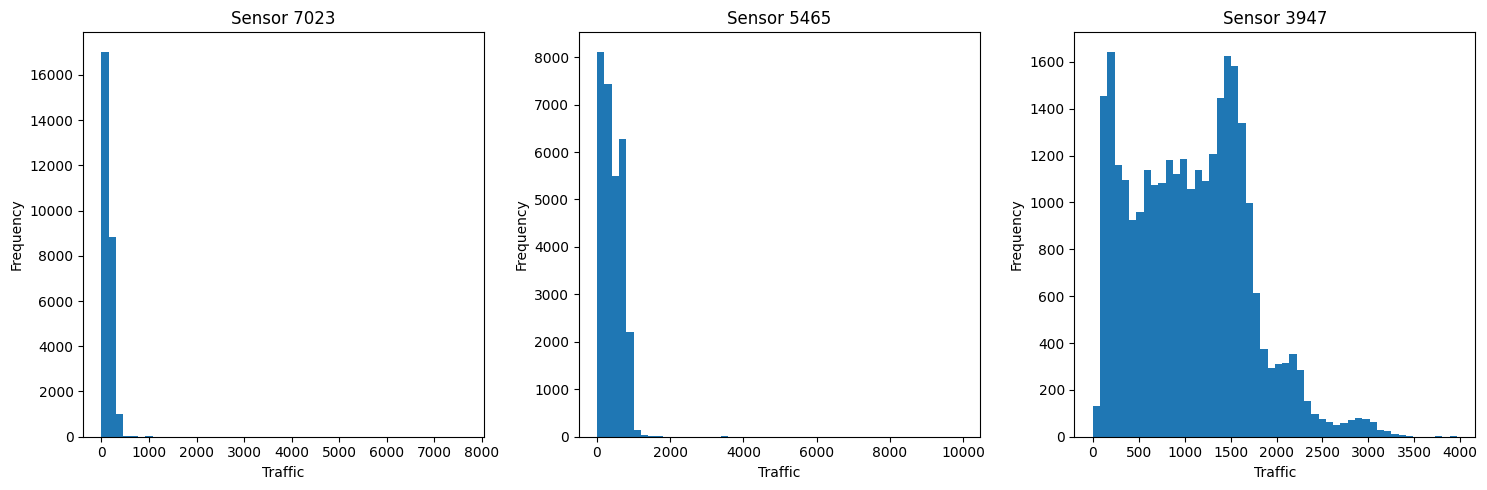

In [27]:
import matplotlib.pyplot as plt

sensors = [7023, 5465, 3947]

fig, axes = plt.subplots(1, 3, figsize=(15,5))

for ax, sensor in zip(axes, sensors):

    temp = con.execute(f"""
    SELECT TRAFFIC_INTENSITY
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID = {sensor}
      AND TRAFFIC_INTENSITY < 10000
    """).df()

    ax.hist(
        temp["TRAFFIC_INTENSITY"],
        bins=50
    )

    ax.set_title(f"Sensor {sensor}")
    ax.set_xlabel("Traffic")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [28]:
sensor_stats = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,

    AVG(TRAFFIC_INTENSITY) AS mean_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,

    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.95) AS p95,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.999) AS p999,

    MAX(TRAFFIC_INTENSITY) AS max_traffic

FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (7023,5465,3947,6845)

GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

sensor_stats

,SENSOR_ID,rows,mean_traffic,median_traffic,p95,p99,p999,max_traffic
0,3947,29051,1069.949308,1058.0,2155.0,2861.2500,3246.9250,90813.000000
1,5465,29788,495.167139,386.0,850.5,993.2275,18692.9480,90910.000000
2,6845,28560,3200.934775,3399.0,5955.0,7125.0000,7140.0000,19614.000000
3,7023,27176,749.455843,124.5,305.0,697.9375,89836.7375,91368.333333


In [29]:
sensor_quality = con.execute(f"""
SELECT
    SENSOR_ID,

    COUNT(*) AS rows,

    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,

    QUANTILE_CONT(TRAFFIC_INTENSITY,0.99) AS p99,

    MAX(TRAFFIC_INTENSITY) AS max_traffic,

    MAX(TRAFFIC_INTENSITY) /
    NULLIF(QUANTILE_CONT(TRAFFIC_INTENSITY,0.99),0)
        AS max_to_p99_ratio

FROM read_parquet('{hourly}')

GROUP BY SENSOR_ID
ORDER BY max_to_p99_ratio DESC
""").df()

sensor_quality.head(20)

,SENSOR_ID,rows,median_traffic,p99,max_traffic,max_to_p99_ratio
0,3624,20222,85.750000,181.4475,25200.000000,138.883148
1,7023,27176,124.500000,697.9375,91368.333333,130.911913
2,4107,25746,48.250000,93.7500,8769.000000,93.536000
3,10674,29794,178.000000,468.8550,42949.666667,91.605436
4,5465,29788,386.000000,993.2275,90910.000000,91.529886
5,5470,27972,318.500000,779.0000,66255.000000,85.051348
6,5377,29085,90.750000,362.4000,27586.250000,76.120999
7,6095,29163,636.250000,1241.8450,73800.000000,59.427706
8,5767,29791,725.500000,1597.8000,89515.500000,56.024221
9,4002,29812,316.000000,714.0000,39060.000000,54.705882


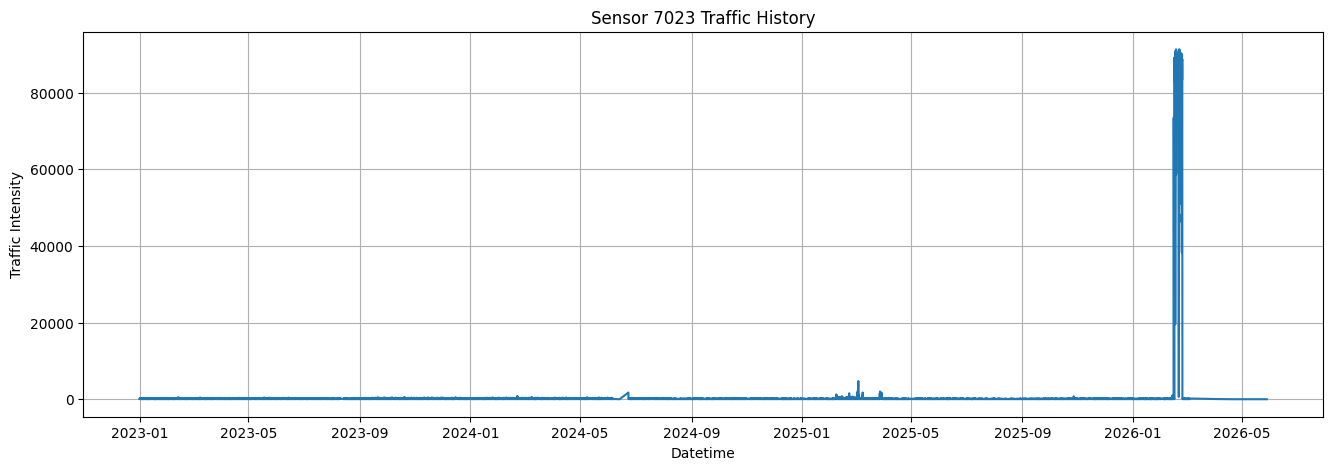

In [30]:
sensor_7023 = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 7023
ORDER BY DATETIME
""").df()

plt.figure(figsize=(16,5))

plt.plot(
    sensor_7023["DATETIME"],
    sensor_7023["TRAFFIC_INTENSITY"]
)

plt.title("Sensor 7023 Traffic History")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.grid(True)
plt.show()

In [31]:
sensor_7023[
    sensor_7023["TRAFFIC_INTENSITY"] > 10000
].sort_values(
    "TRAFFIC_INTENSITY",
    ascending=False
).head(50)

,DATETIME,TRAFFIC_INTENSITY
26892,2026-02-20 22:00:00,91368.333333
26811,2026-02-17 13:00:00,91338.250000
26893,2026-02-20 23:00:00,91269.250000
26801,2026-02-17 03:00:00,91191.500000
26901,2026-02-21 07:00:00,91068.000000
26800,2026-02-17 02:00:00,90986.250000
26812,2026-02-17 14:00:00,90900.250000
26802,2026-02-17 04:00:00,90847.750000
26904,2026-02-21 10:00:00,90835.500000
26876,2026-02-20 06:00:00,90712.000000


In [32]:
sensor_7023_info = con.execute(f"""
SELECT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 7023
LIMIT 1
""").df()

sensor_7023_info

,SENSOR_ID,LONGITUDE,LATITUDE
0,7023,-3.686796,40.401365


In [33]:
sensor_locations = con.execute(f"""
SELECT DISTINCT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{hourly}')
WHERE LONGITUDE IS NOT NULL
  AND LATITUDE IS NOT NULL
""").df()

import pandas as pd
import numpy as np

target_lon = -3.686796
target_lat = 40.401365

sensor_locations["distance"] = np.sqrt(
    (sensor_locations["LONGITUDE"] - target_lon)**2 +
    (sensor_locations["LATITUDE"] - target_lat)**2
)

nearest = (
    sensor_locations
    .sort_values("distance")
    .head(10)
)

nearest

,SENSOR_ID,LONGITUDE,LATITUDE,distance
4068,7023,-3.686796,40.401365,4.793738e-07
1457,4127,-3.685574,40.400373,1.573697e-03
3393,10814,-3.687896,40.399327,2.315977e-03
2901,4129,-3.685758,40.399208,2.393148e-03
2694,4126,-3.684044,40.400538,2.873662e-03
1473,7076,-3.684499,40.399498,2.959965e-03
3600,4145,-3.689476,40.402781,3.031165e-03
805,4146,-3.690846,40.402005,4.100173e-03
2346,7004,-3.683700,40.398582,4.162617e-03
2119,4150,-3.691033,40.400495,4.325804e-03


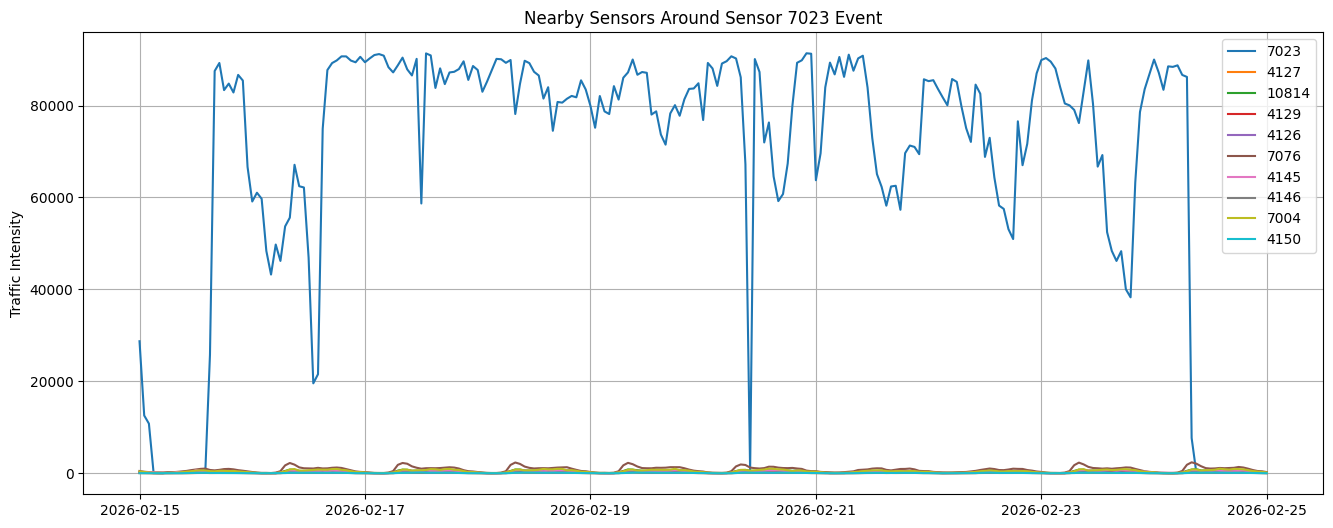

In [34]:
nearby_ids = [
    7023,
    4127,
    10814,
    4129,
    4126,
    7076,
    4145,
    4146,
    7004,
    4150
]

plt.figure(figsize=(16,6))

for sid in nearby_ids:

    temp = con.execute(f"""
    SELECT
        DATETIME,
        TRAFFIC_INTENSITY
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID = {sid}
      AND DATETIME BETWEEN
          '2026-02-15'
          AND
          '2026-02-25'
    ORDER BY DATETIME
    """).df()

    plt.plot(
        temp["DATETIME"],
        temp["TRAFFIC_INTENSITY"],
        label=f"{sid}"
    )

plt.legend()
plt.grid(True)
plt.title("Nearby Sensors Around Sensor 7023 Event")
plt.ylabel("Traffic Intensity")
plt.show()

In [35]:
sensor_3947 = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 3947
ORDER BY DATETIME
""").df()

sensor_3947

,DATETIME,TRAFFIC_INTENSITY
0,2023-01-01 00:00:00,248.50
1,2023-01-01 01:00:00,685.25
2,2023-01-01 02:00:00,666.00
3,2023-01-01 03:00:00,440.25
4,2023-01-01 04:00:00,329.00
...,...,...
29046,2026-05-31 19:00:00,1476.50
29047,2026-05-31 20:00:00,1478.75
29048,2026-05-31 21:00:00,1252.00
29049,2026-05-31 22:00:00,1090.00


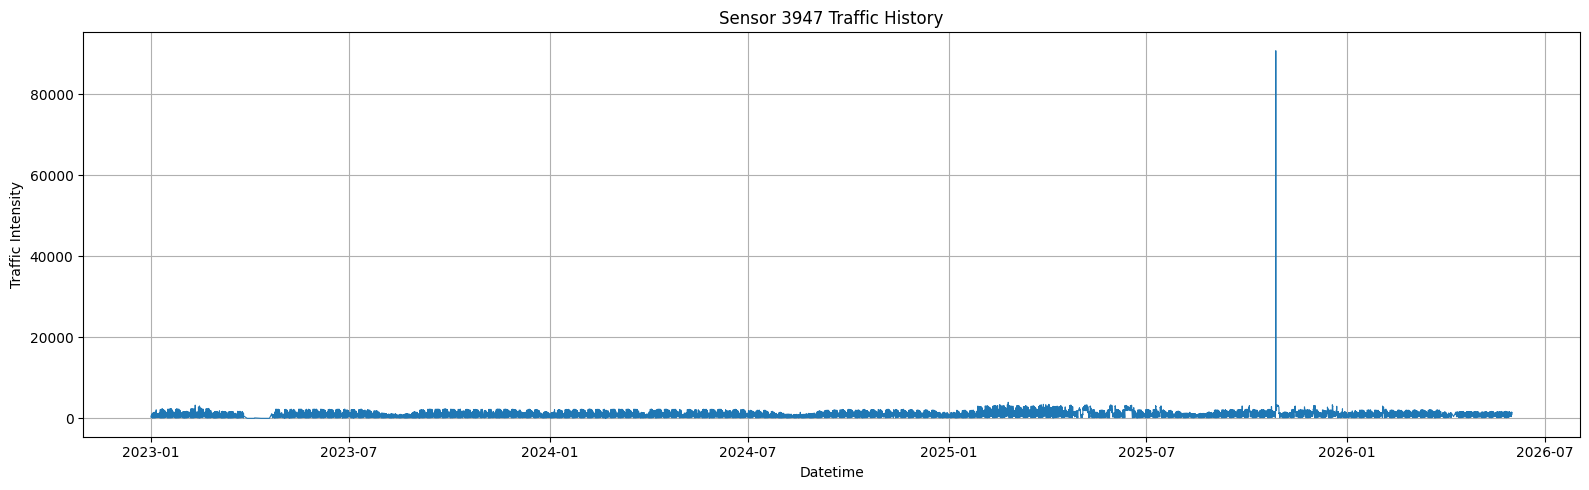

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,5))

plt.plot(
    sensor_3947["DATETIME"],
    sensor_3947["TRAFFIC_INTENSITY"],
    linewidth=0.8
)

plt.title("Sensor 3947 Traffic History")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
sensor_3947_extreme = sensor_3947[
    sensor_3947["TRAFFIC_INTENSITY"] > 10000
].sort_values(
    "TRAFFIC_INTENSITY",
    ascending=False
)

sensor_3947_extreme

,DATETIME,TRAFFIC_INTENSITY
24032,2025-10-27 13:00:00,90813.0


In [38]:
zoom_3947 = sensor_3947[
    (sensor_3947["DATETIME"] >= "2025-10-25") &
    (sensor_3947["DATETIME"] <= "2025-10-29")
]

zoom_3947

,DATETIME,TRAFFIC_INTENSITY
23973,2025-10-25 00:00:00,1114.250000
23974,2025-10-25 01:00:00,863.500000
23975,2025-10-25 02:00:00,648.250000
23976,2025-10-25 03:00:00,498.500000
23977,2025-10-25 04:00:00,481.000000
...,...,...
24057,2025-10-28 14:00:00,3099.500000
24058,2025-10-28 15:00:00,3092.000000
24059,2025-10-28 16:00:00,2996.250000
24060,2025-10-28 17:00:00,3000.750000


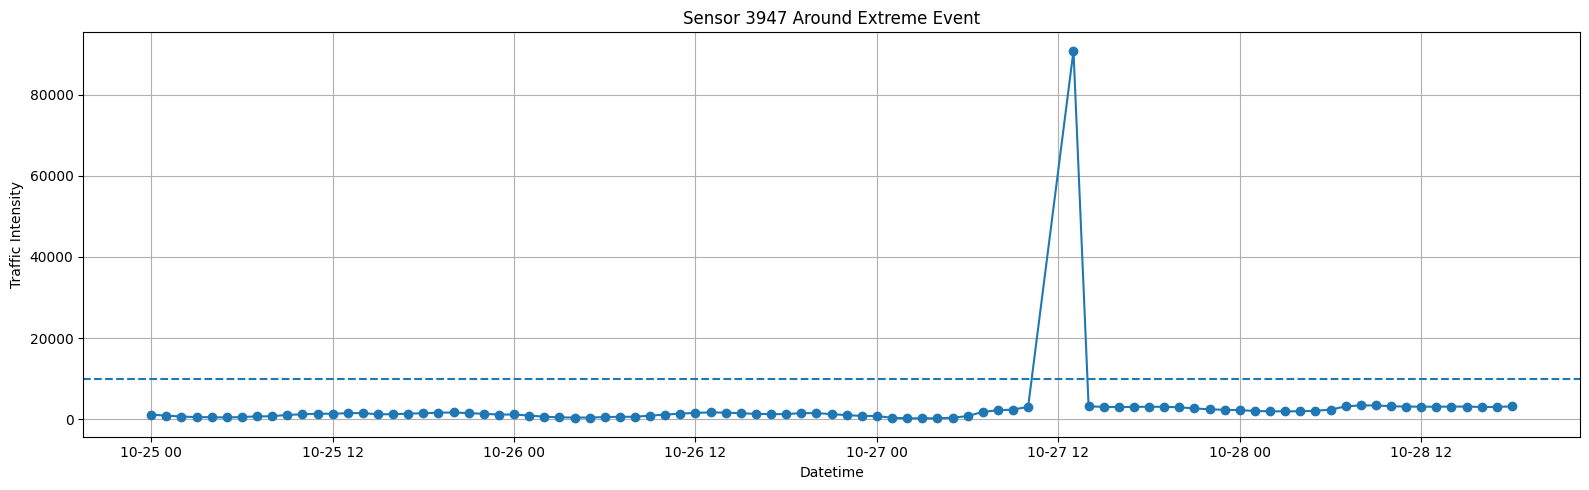

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16,5))

plt.plot(
    zoom_3947["DATETIME"],
    zoom_3947["TRAFFIC_INTENSITY"],
    marker="o"
)

plt.axhline(
    10000,
    linestyle="--"
)

plt.title("Sensor 3947 Around Extreme Event")
plt.xlabel("Datetime")
plt.ylabel("Traffic Intensity")

plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
sensor_thresholds = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.999) AS p999,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

sensor_thresholds.head()

,SENSOR_ID,rows,median_traffic,p99,p999,max_traffic
0,495,4,100.00,158.8,159.88000,160.0
1,1001,16815,1551.00,4560.0,5001.55800,5172.0
2,1002,20070,1320.00,4485.0,4979.09475,5250.0
3,1003,18987,2072.25,5460.0,5796.21000,6018.0
4,1006,27791,1200.00,4497.3,5093.52000,5433.0


In [41]:
anomaly_summary = con.execute(f"""
WITH thresholds AS (
    SELECT
        SENSOR_ID,
        QUANTILE_CONT(TRAFFIC_INTENSITY, 0.999) AS p999
    FROM read_parquet('{hourly}')
    GROUP BY SENSOR_ID
)

SELECT
    t.SENSOR_ID,
    COUNT(*) AS anomaly_rows
FROM read_parquet('{hourly}') d
JOIN thresholds t
    ON d.SENSOR_ID = t.SENSOR_ID
WHERE d.TRAFFIC_INTENSITY > t.p999
GROUP BY t.SENSOR_ID
ORDER BY anomaly_rows DESC
""").df()

anomaly_summary.head(20)

,SENSOR_ID,anomaly_rows
0,5119,30
1,4788,30
2,9995,30
3,4440,30
4,6010,30
5,5176,30
6,10966,30
7,4938,30
8,6687,30
9,10857,30


In [42]:
total_anomalies = anomaly_summary["anomaly_rows"].sum()

total_rows = con.execute(f"""
SELECT COUNT(*) AS n
FROM read_parquet('{hourly}')
""").df()["n"][0]

print(f"Anomaly rows: {total_anomalies:,}")
print(f"Total rows: {total_rows:,}")
print(f"Percentage: {100*total_anomalies/total_rows:.4f}%")

Anomaly rows: 134,214
Total rows: 135,056,283
Percentage: 0.0994%


In [43]:
sensor_ratios = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    MAX(TRAFFIC_INTENSITY) /
        NULLIF(QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99),0)
        AS max_to_p99_ratio
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID
HAVING COUNT(*) > 1000
ORDER BY max_to_p99_ratio DESC
""").df()

In [44]:
sensor_ratios[
    sensor_ratios["max_to_p99_ratio"] >= 20
].shape

(27, 6)

In [45]:
sensor_ratios[
    sensor_ratios["max_to_p99_ratio"] >= 20
].head(30)

,SENSOR_ID,rows,median_traffic,p99,max_traffic,max_to_p99_ratio
0,3624,20222,85.750000,181.447500,25200.000000,138.883148
1,7023,27176,124.500000,697.937500,91368.333333,130.911913
2,4107,25746,48.250000,93.750000,8769.000000,93.536000
3,10674,29794,178.000000,468.855000,42949.666667,91.605436
4,5465,29788,386.000000,993.227500,90910.000000,91.529886
5,5470,27972,318.500000,779.000000,66255.000000,85.051348
6,5377,29085,90.750000,362.400000,27586.250000,76.120999
7,6095,29163,636.250000,1241.845000,73800.000000,59.427706
8,5767,29791,725.500000,1597.800000,89515.500000,56.024221
9,4002,29812,316.000000,714.000000,39060.000000,54.705882


In [46]:
len(sensor_ratios[sensor_ratios["max_to_p99_ratio"] >= 20])

27

In [47]:
total_sensors = con.execute(f"""
SELECT COUNT(DISTINCT SENSOR_ID) AS n
FROM read_parquet('{hourly}')
""").df()

total_sensors

,n
0,4971


In [48]:
con.execute(f"""
SELECT COUNT(DISTINCT SENSOR_ID) AS total_sensors
FROM read_parquet('{hourly}')
""").df()

,total_sensors
0,4971


In [49]:
missing_check = con.execute(f"""
WITH hourly_counts AS (
    SELECT
        SENSOR_ID,
        COUNT(*) AS available_hours
    FROM read_parquet('{hourly}')
    GROUP BY SENSOR_ID
)

SELECT
    MIN(available_hours) AS min_hours,
    AVG(available_hours) AS avg_hours,
    MAX(available_hours) AS max_hours
FROM hourly_counts
""").df()

missing_check

,min_hours,avg_hours,max_hours
0,1,27168.835848,29850


In [50]:
sensor_hours = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS hours_available
FROM read_parquet('{hourly}')
GROUP BY SENSOR_ID
ORDER BY hours_available ASC
LIMIT 20
""").df()

sensor_hours

,SENSOR_ID,hours_available
0,4240,1
1,11349,1
2,2693188,1
3,8448,1
4,262144,1
5,5226,1
6,1002308,1
7,50335653,1
8,170996558,1
9,8637,1


In [51]:
sensor_dist = con.execute(f"""
SELECT
    COUNT(DISTINCT SENSOR_ID) AS total_sensors,
    SUM(CASE WHEN SENSOR_ID < 20000 THEN 1 ELSE 0 END) AS sensors_below_20000,
    SUM(CASE WHEN SENSOR_ID >= 20000 THEN 1 ELSE 0 END) AS sensors_above_20000
FROM (
    SELECT DISTINCT SENSOR_ID
    FROM read_parquet('{hourly}')
)
""").df()

sensor_dist

,total_sensors,sensors_below_20000,sensors_above_20000
0,4971,4964.0,7.0


In [52]:
weird_sensors = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows
FROM read_parquet('{hourly}')
WHERE SENSOR_ID > 20000
GROUP BY SENSOR_ID
ORDER BY rows
LIMIT 50
""").df()

weird_sensors

,SENSOR_ID,rows
0,170996558,1
1,50335653,1
2,1002308,1
3,262144,1
4,2693188,1
5,725876736,2
6,1140850688,3


In [53]:
real_sensor_hours = con.execute(f"""
SELECT
    MIN(hours_available) AS min_hours,
    AVG(hours_available) AS avg_hours,
    MAX(hours_available) AS max_hours
FROM (
    SELECT
        SENSOR_ID,
        COUNT(*) AS hours_available
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID < 20000
    GROUP BY SENSOR_ID
)
""").df()

real_sensor_hours

,min_hours,avg_hours,max_hours
0,1,27207.146052,29850


In [54]:
lowest_real_sensors = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS hours_available
FROM read_parquet('{hourly}')
WHERE SENSOR_ID < 20000
GROUP BY SENSOR_ID
ORDER BY hours_available
LIMIT 20
""").df()

lowest_real_sensors

,SENSOR_ID,hours_available
0,8448,1
1,5226,1
2,8637,1
3,4240,1
4,11349,1
5,5992,3
6,6051,3
7,11346,3
8,495,4
9,10888,5


In [55]:
sensor_completeness = con.execute(f"""
SELECT
    COUNT(*) AS sensors
FROM (
    SELECT
        SENSOR_ID,
        COUNT(*) AS hours_available
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID < 20000
    GROUP BY SENSOR_ID
)
WHERE hours_available < 1000
""").df()

sensor_completeness

,sensors
0,72


In [56]:
sensor_completeness2 = con.execute(f"""
SELECT
    COUNT(*) AS sensors
FROM (
    SELECT
        SENSOR_ID,
        COUNT(*) AS hours_available
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID < 20000
    GROUP BY SENSOR_ID
)
WHERE hours_available >= 20000
""").df()

sensor_completeness2

,sensors
0,4590


In [57]:
sensor_6845["DATETIME"].diff()

0                   NaT
1       0 days 01:00:00
2       0 days 01:00:00
3       0 days 01:00:00
4       0 days 01:00:00
              ...      
28555   0 days 01:00:00
28556   0 days 01:00:00
28557   0 days 01:00:00
28558   0 days 01:00:00
28559   0 days 01:00:00
Name: DATETIME, Length: 28560, dtype: timedelta64[us]

In [58]:
(sensor_3947["DATETIME"].diff() > pd.Timedelta(hours=1)).sum()

np.int64(40)

In [59]:
sensor_7023 = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 7023
ORDER BY DATETIME
""").df()

(sensor_7023["DATETIME"].diff() > pd.Timedelta(hours=1)).sum()

np.int64(28)

In [60]:
sensor_1001 = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 1001
ORDER BY DATETIME
""").df()

(sensor_1001["DATETIME"].diff() > pd.Timedelta(hours=1)).sum()

np.int64(4)

In [61]:
for name, df in [
    ("1001", sensor_1001),
    ("3947", sensor_3947),
    ("7023", sensor_7023),
]:
    gaps = (df["DATETIME"].diff() > pd.Timedelta(hours=1)).sum()
    print(f"Sensor {name}: {gaps} gaps")

Sensor 1001: 4 gaps
Sensor 3947: 40 gaps
Sensor 7023: 28 gaps


In [62]:
gap_3947 = sensor_3947[
    sensor_3947["DATETIME"].diff() > pd.Timedelta(hours=1)
]

gap_3947.head(20)



,DATETIME,TRAFFIC_INTENSITY
1716,2023-03-13 13:00:00,1001.750000
2034,2023-03-29 21:00:00,0.000000
2036,2023-03-30 11:00:00,0.000000
2037,2023-03-30 13:00:00,0.000000
2040,2023-04-05 05:00:00,0.000000
2046,2023-04-05 13:00:00,0.000000
2047,2023-04-05 19:00:00,103.250000
2048,2023-04-11 16:00:00,0.000000
2049,2023-04-19 08:00:00,0.000000
2050,2023-04-19 18:00:00,220.000000


In [63]:
sensor_3947["gap_hours"] = (
    sensor_3947["DATETIME"].diff()
    .dt.total_seconds() / 3600
)

sensor_3947[
    sensor_3947["gap_hours"] > 1
][["DATETIME", "gap_hours"]]

,DATETIME,gap_hours
1716,2023-03-13 13:00:00,2.0
2034,2023-03-29 21:00:00,75.0
2036,2023-03-30 11:00:00,13.0
2037,2023-03-30 13:00:00,2.0
2040,2023-04-05 05:00:00,134.0
2046,2023-04-05 13:00:00,3.0
2047,2023-04-05 19:00:00,6.0
2048,2023-04-11 16:00:00,141.0
2049,2023-04-19 08:00:00,184.0
2050,2023-04-19 18:00:00,10.0


In [64]:
sensor_6845["gap_hours"] = (
    sensor_6845["DATETIME"].diff()
    .dt.total_seconds() / 3600
)

sensor_6845[
    sensor_6845["gap_hours"] > 1
][["DATETIME","gap_hours"]]

,DATETIME,gap_hours
1716,2023-03-13 13:00:00,2.0
15345,2024-11-19 09:00:00,1176.0
15364,2024-11-20 05:00:00,2.0
15378,2024-11-20 20:00:00,2.0
15386,2024-11-21 05:00:00,2.0
15409,2024-11-22 05:00:00,2.0
15552,2024-11-29 00:00:00,21.0
15569,2024-11-30 00:00:00,8.0
15645,2024-12-03 05:00:00,2.0
15884,2024-12-13 05:00:00,2.0


In [65]:
gap_summary = con.execute(f"""
WITH sensor_times AS (
    SELECT
        SENSOR_ID,
        DATETIME,
        LAG(DATETIME) OVER (
            PARTITION BY SENSOR_ID
            ORDER BY DATETIME
        ) AS prev_time
    FROM read_parquet('{hourly}')
),

gaps AS (
    SELECT
        SENSOR_ID,
        DATE_DIFF('hour', prev_time, DATETIME) AS gap_hours
    FROM sensor_times
    WHERE prev_time IS NOT NULL
)

SELECT
    COUNT(*) FILTER (WHERE gap_hours > 1) AS total_gaps,
    COUNT(*) FILTER (WHERE gap_hours > 24) AS gaps_over_24h,
    COUNT(*) FILTER (WHERE gap_hours > 168) AS gaps_over_7days,
    MAX(gap_hours) AS largest_gap
FROM gaps
""").df()

gap_summary

,total_gaps,gaps_over_24h,gaps_over_7days,largest_gap
0,551181,26559,4954,22854


In [66]:
gap_by_sensor = con.execute(f"""
WITH sensor_times AS (
    SELECT
        SENSOR_ID,
        DATETIME,
        LAG(DATETIME) OVER (
            PARTITION BY SENSOR_ID
            ORDER BY DATETIME
        ) AS prev_time
    FROM read_parquet('{hourly}')
),

gaps AS (
    SELECT
        SENSOR_ID,
        DATE_DIFF('hour', prev_time, DATETIME) AS gap_hours
    FROM sensor_times
    WHERE prev_time IS NOT NULL
)

SELECT
    SENSOR_ID,
    COUNT(*) FILTER (WHERE gap_hours > 1) AS n_gaps,
    MAX(gap_hours) AS largest_gap
FROM gaps
GROUP BY SENSOR_ID
ORDER BY n_gaps DESC
LIMIT 20
""").df()

gap_by_sensor

,SENSOR_ID,n_gaps,largest_gap
0,7080,2651,34
1,9967,2461,58
2,5173,2424,34
3,5283,2149,615
4,4479,2055,41
5,6767,2054,31
6,5268,2045,60
7,3737,1955,219
8,4318,1877,66
9,4158,1873,41


In [67]:
temp_stats = con.execute(f"""
SELECT
    MIN(TEMPERATURE) AS min_temp,
    MAX(TEMPERATURE) AS max_temp,
    AVG(TEMPERATURE) AS avg_temp,
    MEDIAN(TEMPERATURE) AS median_temp
FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL
""").df()

temp_stats

,min_temp,max_temp,avg_temp,median_temp
0,-10.6,44.5,15.888822,14.6


In [68]:
precip_stats = con.execute(f"""
SELECT
    MIN(PRECIPITATION) AS min_precip,
    MAX(PRECIPITATION) AS max_precip,
    AVG(PRECIPITATION) AS avg_precip,
    MEDIAN(PRECIPITATION) AS median_precip
FROM read_parquet('{hourly}')
WHERE PRECIPITATION IS NOT NULL
""").df()

precip_stats

,min_precip,max_precip,avg_precip,median_precip
0,0.0,38.4,0.047401,0.0


In [69]:
wind_stats = con.execute(f"""
SELECT
    MIN(WIND_SPEED) AS min_wind,
    MAX(WIND_SPEED) AS max_wind,
    AVG(WIND_SPEED) AS avg_wind,
    MEDIAN(WIND_SPEED) AS median_wind
FROM read_parquet('{hourly}')
WHERE WIND_SPEED IS NOT NULL
""").df()

wind_stats

,min_wind,max_wind,avg_wind,median_wind
0,0.0,8.7,1.140366,0.93


In [70]:
temp_bins = con.execute(f"""
SELECT
    CASE
        WHEN TEMPERATURE < 0 THEN '<0°C'
        WHEN TEMPERATURE < 10 THEN '0-10°C'
        WHEN TEMPERATURE < 20 THEN '10-20°C'
        WHEN TEMPERATURE < 30 THEN '20-30°C'
        WHEN TEMPERATURE < 40 THEN '30-40°C'
        ELSE '>40°C'
    END AS temp_group,

    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic

FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL
GROUP BY 1
ORDER BY 1
""").df()

temp_bins

,temp_group,rows,avg_traffic
0,0-10°C,34735468,290.537631
1,10-20°C,48595661,359.051412
2,20-30°C,29089928,367.366887
3,30-40°C,9314422,420.418271
4,<0°C,978442,207.026847
5,>40°C,99671,359.501205


In [71]:
rain_effect = con.execute(f"""
SELECT
    CASE
        WHEN PRECIPITATION > 0 THEN 'Rain'
        ELSE 'No Rain'
    END AS weather,

    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic

FROM read_parquet('{hourly}')
WHERE PRECIPITATION IS NOT NULL
GROUP BY 1
""").df()

rain_effect

,weather,rows,avg_traffic
0,No Rain,49570296,290.203436
1,Rain,2686779,290.893602


In [72]:
rain_bins = con.execute(f"""
SELECT
    CASE
        WHEN PRECIPITATION = 0 THEN 'No Rain'
        WHEN PRECIPITATION < 1 THEN 'Light Rain'
        WHEN PRECIPITATION < 5 THEN 'Moderate Rain'
        ELSE 'Heavy Rain'
    END AS rain_group,

    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic

FROM read_parquet('{hourly}')
WHERE PRECIPITATION IS NOT NULL
GROUP BY 1
ORDER BY 1
""").df()

rain_bins

,rain_group,rows,avg_traffic
0,Heavy Rain,74437,317.414620
1,Light Rain,1975043,287.560273
2,Moderate Rain,637299,298.126192
3,No Rain,49570296,290.203436


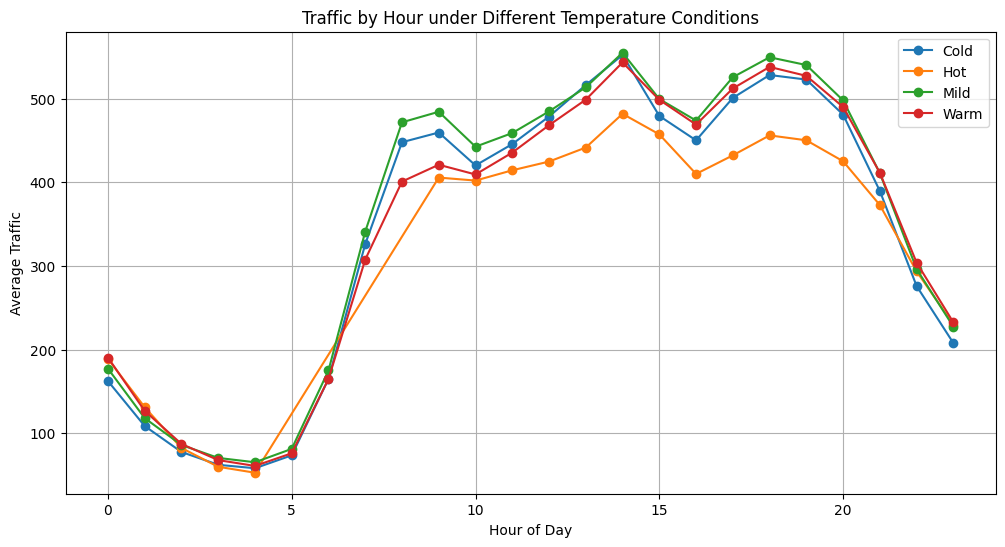

In [73]:
temp_hour = con.execute(f"""
SELECT
    EXTRACT(HOUR FROM DATETIME) AS hour,

    CASE
        WHEN TEMPERATURE < 10 THEN 'Cold'
        WHEN TEMPERATURE < 20 THEN 'Mild'
        WHEN TEMPERATURE < 30 THEN 'Warm'
        ELSE 'Hot'
    END AS temp_group,

    AVG(TRAFFIC_INTENSITY) AS avg_traffic

FROM read_parquet('{hourly}')
WHERE TEMPERATURE IS NOT NULL

GROUP BY 1,2
ORDER BY 1,2
""").df()

plt.figure(figsize=(12,6))

for grp in temp_hour["temp_group"].unique():
    subset = temp_hour[temp_hour["temp_group"] == grp]

    plt.plot(
        subset["hour"],
        subset["avg_traffic"],
        marker="o",
        label=grp
    )

plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic")
plt.title("Traffic by Hour under Different Temperature Conditions")
plt.legend()
plt.grid(True)

plt.show()

In [74]:
hourly = "/home/iai-labor/traffic_project/traffic_weather_hourly_parts/**/*.parquet"

sensor_gap_summary = con.execute(f"""
WITH sensor_hours AS (
    SELECT
        SENSOR_ID,
        COUNT(*) AS hours_available
    FROM read_parquet('{hourly}')
    GROUP BY SENSOR_ID
)

SELECT
    SENSOR_ID,
    hours_available,
    29850 - hours_available AS missing_hours,
    ROUND(
        100.0 * (29850 - hours_available) / 29850,
        2
    ) AS missing_pct
FROM sensor_hours
ORDER BY missing_pct DESC
""").df()

sensor_gap_summary.head(20)

,SENSOR_ID,hours_available,missing_hours,missing_pct
0,1002308,1,29849,100.00
1,4240,1,29849,100.00
2,2693188,1,29849,100.00
3,170996558,1,29849,100.00
4,50335653,1,29849,100.00
5,8448,1,29849,100.00
6,5226,1,29849,100.00
7,8637,1,29849,100.00
8,11349,1,29849,100.00
9,262144,1,29849,100.00


In [75]:
sensor_gap_summary["group"] = pd.cut(
    sensor_gap_summary["missing_pct"],
    bins=[-1, 1, 5, 20, 100],
    labels=[
        "<1%",
        "1-5%",
        "5-20%",
        ">20%"
    ]
)

sensor_gap_summary.groupby("group").size()

group
<1%      2420
1-5%     1141
5-20%     817
>20%      593
dtype: int64

In [76]:
sensor_gap_summary.head(50)

,SENSOR_ID,hours_available,missing_hours,missing_pct,group
0,1002308,1,29849,100.00,>20%
1,4240,1,29849,100.00,>20%
2,2693188,1,29849,100.00,>20%
3,170996558,1,29849,100.00,>20%
4,50335653,1,29849,100.00,>20%
5,8448,1,29849,100.00,>20%
6,5226,1,29849,100.00,>20%
7,8637,1,29849,100.00,>20%
8,11349,1,29849,100.00,>20%
9,262144,1,29849,100.00,>20%


In [77]:
sensor_gap_summary.groupby("group").size()

group
<1%      2420
1-5%     1141
5-20%     817
>20%      593
dtype: int64

In [78]:
sensor_gap_summary.head(20)

,SENSOR_ID,hours_available,missing_hours,missing_pct,group
0,1002308,1,29849,100.00,>20%
1,4240,1,29849,100.00,>20%
2,2693188,1,29849,100.00,>20%
3,170996558,1,29849,100.00,>20%
4,50335653,1,29849,100.00,>20%
5,8448,1,29849,100.00,>20%
6,5226,1,29849,100.00,>20%
7,8637,1,29849,100.00,>20%
8,11349,1,29849,100.00,>20%
9,262144,1,29849,100.00,>20%


In [79]:
sensor_lifetime = con.execute(f"""
WITH sensor_stats AS (
    SELECT
        SENSOR_ID,
        MIN(DATETIME) AS first_time,
        MAX(DATETIME) AS last_time,
        COUNT(*) AS actual_hours
    FROM read_parquet('{hourly}')
    GROUP BY SENSOR_ID
)

SELECT
    SENSOR_ID,
    first_time,
    last_time,
    actual_hours,

    DATE_DIFF(
        'hour',
        first_time,
        last_time
    ) + 1 AS expected_hours,

    ROUND(
        100.0 * actual_hours /
        NULLIF(
            DATE_DIFF('hour', first_time, last_time) + 1,
            0
        ),
        2
    ) AS availability_pct

FROM sensor_stats
ORDER BY availability_pct ASC
""").df()

In [80]:
sensor_lifetime["availability_group"] = pd.cut(
    sensor_lifetime["availability_pct"],
    bins=[0, 50, 80, 95, 100.1],
    labels=[
        "<50%",
        "50-80%",
        "80-95%",
        ">95%"
    ]
)

sensor_lifetime.groupby(
    "availability_group"
).size()

availability_group
<50%        81
50-80%     196
80-95%     830
>95%      3864
dtype: int64

In [81]:
sensor_lifetime.head(30)

,SENSOR_ID,first_time,last_time,actual_hours,expected_hours,availability_pct,availability_group
0,6051,2023-05-24 04:00:00,2024-08-30 12:00:00,3,11145,0.03,<50%
1,5992,2023-06-04 03:00:00,2024-04-10 04:00:00,3,7466,0.04,<50%
2,1140850688,2023-01-23 08:00:00,2023-08-26 02:00:00,3,5155,0.06,<50%
3,495,2023-08-25 10:00:00,2024-03-29 00:00:00,4,5199,0.08,<50%
4,11380,2025-01-29 13:00:00,2026-05-30 00:00:00,140,11652,1.20,<50%
5,725876736,2023-02-06 16:00:00,2023-02-13 01:00:00,2,154,1.30,<50%
6,5993,2023-01-29 06:00:00,2026-04-27 18:00:00,762,28429,2.68,<50%
7,6050,2023-02-07 03:00:00,2026-04-27 03:00:00,763,28201,2.71,<50%
8,5867,2023-03-26 14:00:00,2026-05-25 18:00:00,755,27749,2.72,<50%
9,10869,2023-01-11 09:00:00,2026-02-28 18:00:00,754,27466,2.75,<50%


In [82]:
gap_distribution = con.execute(f"""
WITH sensor_times AS (
    SELECT
        SENSOR_ID,
        DATETIME,
        LAG(DATETIME) OVER (
            PARTITION BY SENSOR_ID
            ORDER BY DATETIME
        ) AS prev_time
    FROM read_parquet('{hourly}')
),

gaps AS (
    SELECT
        DATE_DIFF('hour', prev_time, DATETIME) AS gap_hours
    FROM sensor_times
    WHERE prev_time IS NOT NULL
      AND DATE_DIFF('hour', prev_time, DATETIME) > 1
)

SELECT
    CASE
        WHEN gap_hours = 2 THEN '2h'
        WHEN gap_hours BETWEEN 3 AND 6 THEN '3-6h'
        WHEN gap_hours BETWEEN 7 AND 24 THEN '7-24h'
        WHEN gap_hours BETWEEN 25 AND 168 THEN '1-7d'
        ELSE '>7d'
    END AS gap_group,

    COUNT(*) AS gaps

FROM gaps
GROUP BY 1
ORDER BY 1
""").df()

gap_distribution

,gap_group,gaps
0,1-7d,21605
1,2h,270940
2,3-6h,176695
3,7-24h,76987
4,>7d,4954


In [83]:
bad_sensors = sensor_lifetime[
    sensor_lifetime["availability_pct"] < 50
]["SENSOR_ID"].tolist()

print(len(bad_sensors))

81


In [84]:
sensor_selection = con.execute(f"""
WITH sensor_stats AS (
    SELECT
        SENSOR_ID,

        COUNT(*) AS rows,

        AVG(TRAFFIC_INTENSITY) AS mean_traffic,
        MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
        STDDEV(TRAFFIC_INTENSITY) AS std_traffic,

        MIN(DATETIME) AS first_time,
        MAX(DATETIME) AS last_time

    FROM read_parquet('{hourly}')
    GROUP BY SENSOR_ID
)

SELECT *
FROM sensor_stats
WHERE rows > 25000
ORDER BY std_traffic DESC
LIMIT 50
""").df()

sensor_selection

,SENSOR_ID,rows,mean_traffic,median_traffic,std_traffic,first_time,last_time
0,7023,27176,749.455843,124.500,6971.734851,2023-01-01,2026-05-28 12:00:00
1,3819,29850,3938.973018,4345.250,2415.021884,2023-01-01,2026-05-31 23:00:00
2,6666,29255,3681.994357,4011.250,2252.558666,2023-01-01,2026-05-31 23:00:00
3,5465,29788,495.167139,386.000,2226.390322,2023-01-01,2026-05-31 23:00:00
4,6679,29810,3583.723314,4041.750,2201.929554,2023-01-01,2026-05-31 23:00:00
5,6727,26876,3391.298600,3530.125,2136.209361,2023-01-01,2026-05-31 23:00:00
6,3799,29783,3471.231421,3908.250,2121.638820,2023-01-01,2026-05-31 23:00:00
7,6842,28610,3293.197361,3561.000,2019.094415,2023-01-01,2026-05-31 23:00:00
8,6642,29850,2917.360282,2937.000,2017.077861,2023-01-01,2026-05-31 23:00:00
9,6845,28560,3200.934775,3399.000,1986.503309,2023-01-01,2026-05-31 23:00:00


In [85]:
candidate_sensors = [6642, 10265, 6654]

comparison = con.execute(f"""
SELECT
    SENSOR_ID,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS mean_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    STDDEV(TRAFFIC_INTENSITY) AS std_traffic,
    MIN(TRAFFIC_INTENSITY) AS min_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic
FROM read_parquet('{hourly}')
WHERE SENSOR_ID IN (6642,10265,6654)
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

comparison

,SENSOR_ID,rows,mean_traffic,median_traffic,std_traffic,min_traffic,max_traffic
0,6642,29850,2917.360282,2937.00,2017.077861,0.0,6793.50
1,6654,29849,2644.300119,2666.25,1783.781376,0.0,6004.00
2,10265,29850,2721.186410,2951.25,1680.873868,0.0,5884.25


In [86]:
for sid in [6642, 10265, 6654]:

    df_sensor = con.execute(f"""
    SELECT
        DATETIME,
        TRAFFIC_INTENSITY
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID = {sid}
    ORDER BY DATETIME
    """).df()

    print("\nSensor:", sid)
    print(df_sensor.nlargest(10, "TRAFFIC_INTENSITY"))


Sensor: 6642
                 DATETIME  TRAFFIC_INTENSITY
10516 2024-03-14 08:00:00        6793.500000
10156 2024-02-28 08:00:00        6779.000000
3631  2023-06-01 08:00:00        6763.250000
19512 2025-03-24 08:00:00        6760.250000
1759  2023-03-15 08:00:00        6736.500000
3583  2023-05-30 08:00:00        6728.250000
19224 2025-03-12 08:00:00        6727.000000
3559  2023-05-29 08:00:00        6723.250000
19560 2025-03-26 08:00:00        6719.250000
3391  2023-05-22 08:00:00        6715.333333

Sensor: 10265
                 DATETIME  TRAFFIC_INTENSITY
256   2023-01-11 16:00:00            5884.25
1070  2023-02-14 14:00:00            5778.00
3295  2023-05-18 08:00:00            5754.00
18696 2025-02-18 08:00:00            5725.25
20310 2025-04-26 14:00:00            5723.75
10282 2024-03-04 14:00:00            5714.00
17215 2024-12-18 13:00:00            5710.00
2488  2023-04-14 17:00:00            5706.75
20208 2025-04-22 08:00:00            5690.50
11794 2024-05-06 14:00:00 

In [87]:
sensor = con.execute(f"""
SELECT
    DATETIME,
    TRAFFIC_INTENSITY
FROM read_parquet('{hourly}')
WHERE SENSOR_ID = 6642
ORDER BY DATETIME
""").df()

sensor["gap_hours"] = (
    sensor["DATETIME"]
    .diff()
    .dt.total_seconds()/3600
)

gaps = sensor[
    sensor["gap_hours"] > 1
]

print("Number of gaps:", len(gaps))

gaps.head(20)

Number of gaps: 11


,DATETIME,TRAFFIC_INTENSITY,gap_hours
1716,2023-03-13 13:00:00,3600.000000,2.0
5426,2023-08-15 06:00:00,84.000000,4.0
13497,2024-07-16 15:00:00,2969.333333,3.0
18234,2025-01-30 02:00:00,258.000000,3.0
20360,2025-04-29 04:00:00,7.000000,13.0
20365,2025-04-30 14:00:00,3320.000000,30.0
21497,2025-06-16 21:00:00,2331.500000,4.0
25067,2025-11-12 20:00:00,4854.000000,6.0
26054,2025-12-24 00:00:00,1416.250000,2.0
28310,2026-03-28 02:00:00,626.750000,3.0


In [88]:
import numpy as np

sensor_test = sensor.copy()

np.random.seed(42)

mask_idx = np.random.choice(
    sensor_test.index,
    size=int(len(sensor_test) * 0.05),
    replace=False
)

true_values = sensor_test.loc[
    mask_idx,
    "TRAFFIC_INTENSITY"
].copy()

sensor_test.loc[
    mask_idx,
    "TRAFFIC_INTENSITY"
] = np.nan

In [89]:
linear = sensor_test.copy()

linear = linear.set_index("DATETIME")

linear["TRAFFIC_INTENSITY"] = (
    linear["TRAFFIC_INTENSITY"]
    .interpolate(method="time")
)

linear = linear.reset_index()

In [92]:
linear

,DATETIME,TRAFFIC_INTENSITY,gap_hours
0,2023-01-01 00:00:00,953.50,NaN
1,2023-01-01 01:00:00,4080.00,1.0
2,2023-01-01 02:00:00,3260.00,1.0
3,2023-01-01 03:00:00,1511.25,1.0
4,2023-01-01 04:00:00,831.50,1.0
...,...,...,...
29845,2026-05-31 19:00:00,4037.25,1.0
29846,2026-05-31 20:00:00,2805.50,1.0
29847,2026-05-31 21:00:00,2840.50,1.0
29848,2026-05-31 22:00:00,2263.75,1.0


In [90]:
daily = sensor_test.copy()

daily["TRAFFIC_INTENSITY"] = (
    daily["TRAFFIC_INTENSITY"]
    .fillna(
        daily["TRAFFIC_INTENSITY"].shift(24)
    )
)

In [93]:
daily

,DATETIME,TRAFFIC_INTENSITY,gap_hours
0,2023-01-01 00:00:00,953.50,NaN
1,2023-01-01 01:00:00,4080.00,1.0
2,2023-01-01 02:00:00,3260.00,1.0
3,2023-01-01 03:00:00,1511.25,1.0
4,2023-01-01 04:00:00,831.50,1.0
...,...,...,...
29845,2026-05-31 19:00:00,4037.25,1.0
29846,2026-05-31 20:00:00,2805.50,1.0
29847,2026-05-31 21:00:00,2840.50,1.0
29848,2026-05-31 22:00:00,2263.75,1.0


In [91]:
daily["TRAFFIC_INTENSITY"] = (
    daily["TRAFFIC_INTENSITY"]
    .interpolate()
)

In [94]:
daily

,DATETIME,TRAFFIC_INTENSITY,gap_hours
0,2023-01-01 00:00:00,953.50,NaN
1,2023-01-01 01:00:00,4080.00,1.0
2,2023-01-01 02:00:00,3260.00,1.0
3,2023-01-01 03:00:00,1511.25,1.0
4,2023-01-01 04:00:00,831.50,1.0
...,...,...,...
29845,2026-05-31 19:00:00,4037.25,1.0
29846,2026-05-31 20:00:00,2805.50,1.0
29847,2026-05-31 21:00:00,2840.50,1.0
29848,2026-05-31 22:00:00,2263.75,1.0


In [95]:
weekly = sensor_test.copy()

weekly["TRAFFIC_INTENSITY"] = (
    weekly["TRAFFIC_INTENSITY"]
    .fillna(
        weekly["TRAFFIC_INTENSITY"].shift(24*7)
    )
)

weekly["TRAFFIC_INTENSITY"] = (
    weekly["TRAFFIC_INTENSITY"]
    .interpolate()
)

In [96]:
weekly

,DATETIME,TRAFFIC_INTENSITY,gap_hours
0,2023-01-01 00:00:00,953.50,NaN
1,2023-01-01 01:00:00,4080.00,1.0
2,2023-01-01 02:00:00,3260.00,1.0
3,2023-01-01 03:00:00,1511.25,1.0
4,2023-01-01 04:00:00,831.50,1.0
...,...,...,...
29845,2026-05-31 19:00:00,4037.25,1.0
29846,2026-05-31 20:00:00,2805.50,1.0
29847,2026-05-31 21:00:00,2840.50,1.0
29848,2026-05-31 22:00:00,2263.75,1.0


In [98]:
for name, df_method in [
    ("Linear", linear),
    ("Daily", daily),
    ("Weekly", weekly)
]:
    print(
        name,
        df_method.loc[
            mask_idx,
            "TRAFFIC_INTENSITY"
        ].isna().sum()
    )

Linear 0
Daily 0
Weekly 0


In [99]:
import numpy as np
import pandas as pd

results = []

for name, df_method in [
    ("Linear", linear),
    ("Daily", daily),
    ("Weekly", weekly)
]:

    pred = df_method.loc[
        mask_idx,
        "TRAFFIC_INTENSITY"
    ].values

    true = true_values.values

    mae = np.mean(np.abs(true - pred))

    rmse = np.sqrt(
        np.mean((true - pred) ** 2)
    )

    results.append([
        name,
        mae,
        rmse
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Method",
        "MAE",
        "RMSE"
    ]
)

print(results_df)

   Method         MAE         RMSE
0  Linear  334.811020   479.111758
1   Daily  655.534964  1128.388893
2  Weekly  645.488829  1128.091697


In [100]:
bad_sensors = sensor_lifetime[
    sensor_lifetime["availability_pct"] < 50
]["SENSOR_ID"].tolist()

len(bad_sensors)

81

In [101]:
bad_sensors_df = sensor_lifetime[
    sensor_lifetime["availability_pct"] < 50
].copy()

bad_sensors_df.to_csv(
    "/home/iai-labor/traffic_project/bad_sensors_removed.csv",
    index=False
)

In [102]:
bad_sensors_str = ",".join(map(str, bad_sensors))

clean_base = "/home/iai-labor/traffic_project/traffic_hourly_clean_base.parquet"

con.execute(f"""
COPY (
    SELECT *
    FROM read_parquet('{hourly}')
    WHERE SENSOR_ID NOT IN ({bad_sensors_str})
)
TO '{clean_base}'
(FORMAT PARQUET)
""")

In [103]:
con.execute(f"""
SELECT
    COUNT(*) AS rows_after_removal,
    COUNT(DISTINCT SENSOR_ID) AS sensors_after_removal
FROM read_parquet('{clean_base}')
""").df()

,rows_after_removal,sensors_after_removal
0,134683654,4890


In [104]:
from pathlib import Path
import pandas as pd
import numpy as np

clean_base = "/home/iai-labor/traffic_project/traffic_hourly_clean_base.parquet"
output_dir = Path("/home/iai-labor/traffic_project/traffic_hourly_imputed_parts")

output_dir.mkdir(parents=True, exist_ok=True)

sensor_ids = con.execute(f"""
SELECT DISTINCT SENSOR_ID
FROM read_parquet('{clean_base}')
ORDER BY SENSOR_ID
""").df()["SENSOR_ID"].tolist()

len(sensor_ids)

4890

In [105]:
for i, sid in enumerate(sensor_ids, start=1):

    if i % 100 == 0:
        print(f"Processing sensor {i}/{len(sensor_ids)}: {sid}")

    df = con.execute(f"""
    SELECT *
    FROM read_parquet('{clean_base}')
    WHERE SENSOR_ID = {sid}
    ORDER BY DATETIME
    """).df()

    df["DATETIME"] = pd.to_datetime(df["DATETIME"])
    df = df.sort_values("DATETIME")

    # Reindex to full hourly range inside this sensor lifetime
    full_index = pd.date_range(
        start=df["DATETIME"].min(),
        end=df["DATETIME"].max(),
        freq="h"
    )

    df = df.set_index("DATETIME").reindex(full_index)
    df.index.name = "DATETIME"

    # Restore sensor id
    df["SENSOR_ID"] = sid

    # Mark originally missing rows
    df["WAS_MISSING_ROW"] = df["TRAFFIC_INTENSITY"].isna().astype("int8")

    # Gap length helper
    missing = df["TRAFFIC_INTENSITY"].isna()
    group_id = (missing != missing.shift()).cumsum()
    gap_len = missing.groupby(group_id).transform("sum")
    df["GAP_LENGTH_HOURS"] = np.where(missing, gap_len, 0).astype("int32")

    # Impute traffic-related numeric fields only for gaps <= 24h
    traffic_cols = [
        "TRAFFIC_INTENSITY",
        "OCCUPANCY",
        "LOAD",
        "AVERAGE_SPEED",
        "INTEGRATION_PERIOD"
    ]

    for col in traffic_cols:
        if col in df.columns:
            interpolated = df[col].interpolate(method="time", limit_area="inside")
            mask = df[col].isna() & (df["GAP_LENGTH_HOURS"] <= 24)
            df.loc[mask, col] = interpolated.loc[mask]

    # Forward/backward fill static columns inside same sensor
    static_cols = [
        "ELEMENT_TYPE",
        "LONGITUDE",
        "LATITUDE",
        "NEAREST_WEATHER_STATION_CODE",
        "NEAREST_WEATHER_STATION_NAME",
        "DISTANCE_TO_WEATHER_KM",
        "year",
        "month"
    ]

    for col in static_cols:
        if col in df.columns:
            df[col] = df[col].ffill().bfill()

    # Keep error flag as original where available, mark imputed rows separately
    if "ERROR_FLAG" in df.columns:
        df["ERROR_FLAG"] = df["ERROR_FLAG"].ffill().bfill()

    df["IS_IMPUTED"] = (
        (df["WAS_MISSING_ROW"] == 1) &
        (df["TRAFFIC_INTENSITY"].notna())
    ).astype("int8")

    df = df.reset_index()

    out_file = output_dir / f"sensor_{sid}.parquet"
    df.to_parquet(out_file, index=False)

Processing sensor 100/4890: 3453
Processing sensor 200/4890: 3568
Processing sensor 300/4890: 3674
Processing sensor 400/4890: 3783
Processing sensor 500/4890: 3887
Processing sensor 600/4890: 4002
Processing sensor 700/4890: 4110
Processing sensor 800/4890: 4216
Processing sensor 900/4890: 4340
Processing sensor 1000/4890: 4451
Processing sensor 1100/4890: 4566
Processing sensor 1200/4890: 4672
Processing sensor 1300/4890: 4780
Processing sensor 1400/4890: 4891
Processing sensor 1500/4890: 5003
Processing sensor 1600/4890: 5112
Processing sensor 1700/4890: 5217
Processing sensor 1800/4890: 5325
Processing sensor 1900/4890: 5433
Processing sensor 2000/4890: 5545
Processing sensor 2100/4890: 5647
Processing sensor 2200/4890: 5749
Processing sensor 2300/4890: 5853
Processing sensor 2400/4890: 5959
Processing sensor 2500/4890: 6071
Processing sensor 2600/4890: 6173
Processing sensor 2700/4890: 6279
Processing sensor 2800/4890: 6387
Processing sensor 2900/4890: 6488
Processing sensor 3000/

In [2]:
import duckdb
con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"

con.execute(f"""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT SENSOR_ID) AS total_sensors,
    SUM(WAS_MISSING_ROW) AS inserted_missing_rows,
    SUM(IS_IMPUTED) AS imputed_rows
FROM read_parquet('{imputed_path}')
""").df()

,total_rows,total_sensors,inserted_missing_rows,imputed_rows
0,139977293,4890,5293639.0,1566793.0


In [3]:
con.execute(f"""
SELECT
    COUNT(*) AS total_rows,
    SUM(CASE WHEN TRAFFIC_INTENSITY IS NULL THEN 1 ELSE 0 END) AS remaining_missing_traffic,
    ROUND(
        100.0 * SUM(CASE WHEN TRAFFIC_INTENSITY IS NULL THEN 1 ELSE 0 END) / COUNT(*),
        4
    ) AS remaining_missing_pct
FROM read_parquet('{imputed_path}')
""").df()

,total_rows,remaining_missing_traffic,remaining_missing_pct
0,139977293,3726846.0,2.6625


In [4]:
con.execute(f"""
SELECT
    CASE
        WHEN GAP_LENGTH_HOURS <= 24 THEN '<=24h'
        WHEN GAP_LENGTH_HOURS <= 168 THEN '1-7d'
        ELSE '>7d'
    END AS gap_type,

    COUNT(*) AS remaining_missing

FROM read_parquet('{imputed_path}')
WHERE TRAFFIC_INTENSITY IS NULL

GROUP BY 1
ORDER BY 1
""").df()

,gap_type,remaining_missing
0,1-7d,1040180
1,>7d,2686666


In [ ]:
import duckdb
con = duckdb.connect()
imputed_path = "/home/iai-labor/traffic_project/traffic_hourly_imputed_parts/*.parquet"
sensor_map_table = con.execute(f"""
SELECT
    SENSOR_ID,
    ANY_VALUE(ELEMENT_TYPE) AS ELEMENT_TYPE,
    ANY_VALUE(LONGITUDE) AS LONGITUDE,
    ANY_VALUE(LATITUDE) AS LATITUDE,
    COUNT(*) AS rows,
    AVG(TRAFFIC_INTENSITY) AS avg_traffic,
    MEDIAN(TRAFFIC_INTENSITY) AS median_traffic,
    MAX(TRAFFIC_INTENSITY) AS max_traffic,
    QUANTILE_CONT(TRAFFIC_INTENSITY, 0.99) AS p99_traffic
FROM read_parquet('{imputed_path}')
WHERE SENSOR_ID IS NOT NULL
  AND LONGITUDE IS NOT NULL
  AND LATITUDE IS NOT NULL
GROUP BY SENSOR_ID
ORDER BY SENSOR_ID
""").df()

sensor_map_table.head()

In [2]:
sensor_map_table.to_csv(
    "/home/iai-labor/traffic_project/sensor_map_table.csv",
    index=False
)

sensor_map_table.shape

(4845, 9)

In [3]:
con.execute(f"""
SELECT
    COUNT(DISTINCT SENSOR_ID) AS sensors_total,

    COUNT(DISTINCT CASE
        WHEN LONGITUDE IS NOT NULL
         AND LATITUDE IS NOT NULL
        THEN SENSOR_ID
    END) AS sensors_with_coords,

    COUNT(DISTINCT CASE
        WHEN LONGITUDE IS NULL
          OR LATITUDE IS NULL
        THEN SENSOR_ID
    END) AS sensors_without_coords

FROM read_parquet('{imputed_path}')
""").df()

,sensors_total,sensors_with_coords,sensors_without_coords
0,4890,4845,45


In [4]:
missing_coords = con.execute(f"""
SELECT DISTINCT
    SENSOR_ID,
    LONGITUDE,
    LATITUDE
FROM read_parquet('{imputed_path}')
WHERE LONGITUDE IS NULL
   OR LATITUDE IS NULL
ORDER BY SENSOR_ID
""").df()

missing_coords

,SENSOR_ID,LONGITUDE,LATITUDE
0,3618,NaN,NaN
1,3662,NaN,NaN
2,3731,NaN,NaN
3,3791,NaN,NaN
4,3904,NaN,NaN
5,4096,NaN,NaN
6,4152,NaN,NaN
7,4240,NaN,NaN
8,4303,NaN,NaN
9,4757,NaN,NaN
